<a href="https://colab.research.google.com/github/SantiagoGuz13/Trabajo-/blob/main/Segundo_Laboratotio_2222809.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Análisis Numérico** <br>
**David Santiago Guzman Diaz-2222809**<br>
**Profesor Julio C. Carrillo E.** <br>
**Universidad Industrial de Santander — Escuela de Matemáticas**

---

#Métodos cerrados, iteración de punto fijo, aceleración de la convergencia y ceros de polinomios

---
## Parte 0. Módulo común y utilidades de diagnóstico

Todos los métodos del laboratorio comparten una misma interfaz, lo que permite compararlos con un único código de análisis.

**0.1 Interfaz.** Cada método devuelve un objeto `ResultadoRaiz` (definido en la celda siguiente, no lo modifique) con los campos `root`, `iterations`, `function_calls`, `converged`, `flag`, `history` y `extra`.

**0.2 Costo.** El costo de un método se mide en evaluaciones de la función (Definición 1.4.15), no en iteraciones. Implemente la clase `ContadorEvaluaciones`, que envuelve una función y cuenta cuántas veces se evalúa. Cada método debe envolver su función de entrada con ella y reportar `function_calls` a partir del contador, nunca a partir del número de iteraciones.

**0.3 Criterio de parada.** Implemente `criterio_parada(x_nuevo, x_viejo, fx_nuevo, tol_a, tol_r, tol_f)` con el criterio combinado de la Observación 1.4.11:
$$|x_n-x_{n-1}| < \varepsilon_a + \varepsilon_r|x_n| \quad\text{y}\quad |f(x_n)| < \varepsilon_f .$$

**0.4 Diagnóstico.** Implemente:
- `acoc(xs)`: orden de convergencia computacional aproximado $\hat\alpha_n$ de la Definición 1.4.8, que no requiere conocer $p$;
- `orden_con_error(xs, p, umbral)`: el mismo cociente calculado con los errores verdaderos $e_n = x_n - p$;
- `cociente_con_signo(xs, p, umbral)`: los cocientes $(p-x_{n+1})/(p-x_n)$, cuyo límite es $g'(p)$ en una iteración de punto fijo lineal (Teorema 1.6.6(iv)).

Las dos últimas descartan los errores menores que `umbral`, pues ya están dominados por el redondeo (Teorema 1.3.10) y no contienen información sobre la convergencia.

In [84]:
# Bibliotecas permitidas: Python estándar, NumPy y (solo para graficar) Matplotlib.
import math
from dataclasses import dataclass, field

import numpy as np
import matplotlib.pyplot as plt

# Unidad de redondeo de la doble precisión IEEE 754 (Definición 1.1.11): u = 2^-53.
U_REDONDEO = np.finfo(float).eps / 2.0

# Estilo de las gráficas: paleta categórica en orden fijo, más un marcador y un
# tipo de línea por serie, para que la identidad de cada serie no dependa solo del color.
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7"]
MARCADORES = ["o", "s", "^", "D", "v", "P", "X"]
LINEAS = ["-", "--", "-.", ":", "-", "--", "-."]
plt.rcParams.update({
    "figure.figsize": (7.5, 4.5), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.6, "lines.markersize": 5, "legend.fontsize": 9,
})


@dataclass
class ResultadoRaiz:
    """Salida común de todos los métodos del laboratorio (no modificar).

    root           : última aproximación calculada (float o complex).
    iterations     : número de iteraciones realizadas.
    function_calls : número de evaluaciones de la función (f o g).
    converged      : True solo si se satisfizo el criterio de parada.
    flag           : motivo de terminación ('convergencia', 'iteraciones agotadas', ...).
    history        : numpy.ndarray con la sucesión completa x_0, x_1, ..., x_N.
    extra          : información adicional propia de cada método.
    """

    root: float
    iterations: int
    function_calls: int
    converged: bool
    flag: str
    history: np.ndarray
    extra: dict = field(default_factory=dict)

In [85]:
class ContadorEvaluaciones:
    """Envoltorio que cuenta las evaluaciones de una función (Definición 1.4.15).

    Uso: f = ContadorEvaluaciones(f); f(x) evalúa y suma 1 a f.llamadas.
    """
    def __init__(self, f):
        self.f = f
        self.llamadas = 0

    def __call__(self, x):
        self.llamadas += 1
        return self.f(x)

class ContadorEvaluaciones:
    def __init__(self, func):
        self.func = func
        self.evaluaciones = 0

    def __call__(self, x):
        self.evaluaciones += 1
        return self.func(x)

In [86]:
def criterio_parada(x_nuevo, x_viejo, fx_nuevo, tol_a, tol_r, tol_f):
    """Criterio de parada combinado de la Observación 1.4.11:
    |x_n - x_{n-1}| < tol_a + tol_r * |x_n|   Y   |f(x_n)| < tol_f
    """
    condicion_x = abs(x_nuevo - x_viejo) < (tol_a + tol_r * abs(x_nuevo))
    condicion_f = abs(fx_nuevo) < tol_f
    return condicion_x and condicion_f

**ACOC (ORDEN DE CONVERGENCIA COMPUTACIONAL APROXIMADO)**

In [87]:
def acoc(xs):
    """Orden de convergencia computacional aproximado (Definición 1.4.8).

    Devuelve un numpy.ndarray con los valores alpha_n. Descarte los incrementos nulos.
    """
    xs = np.asarray(xs, dtype=float)
    alpha_n = []

    for i in range(2, len(xs) - 1):
        # Términos de la Definición 1.4.8
        num_ratio = abs(xs[i+1] - xs[i]) / abs(xs[i] - xs[i-1]) #Numerador
        den_ratio = abs(xs[i] - xs[i-1]) / abs(xs[i-1] - xs[i-2]) #Denominador
        # Evitar divisiones por cero o logaritmos de cero/negativos
        if den_ratio > 0 and num_ratio > 0 and abs(xs[i] - xs[i-1]) > 0 and abs(xs[i-1] - xs[i-2]) > 0:
            val = np.log(num_ratio) / np.log(den_ratio)
            alpha_n.append(val)
        else:
            alpha_n.append(np.nan) #Ayuda para el denominador cero o negativo

    return np.array(alpha_n)

**ORDEN DE CONVERGENCIA EMPÍRICO**

In [88]:
def orden_con_error(xs, p, umbral=1e-13):
    """Orden empírico con los errores verdaderos e_n = x_n - p (descarta |e_n| <= umbral)."""
    xs = np.asarray(xs, dtype=float)
    es = xs - p  # Errores verdaderos e_n = x_n - p
    alpha_n = []

    for i in range(1, len(es) - 1):
        e_ant = abs(es[i-1])
        e_act = abs(es[i])
        e_sig = abs(es[i+1])

        # Verificar el umbral
        if e_ant > umbral and e_act > umbral and e_sig > umbral:
            num_ratio = e_sig / e_act
            den_ratio = e_act / e_ant

            # Evitar logaritmos de cero o negativos
            if den_ratio > 0 and num_ratio > 0:
                val = np.log(num_ratio) / np.log(den_ratio)
                alpha_n.append(val)
            else:
                alpha_n.append(np.nan)
        else:
            alpha_n.append(np.nan)  # Relleno para los que son menores al umbral

    return np.array(alpha_n)

**COCIENTES CONSECUTIVOS**

In [89]:
def cociente_con_signos(xs, p, umbral=1e-13):
    """Calcula los cocientes con signo (p - x_{n+1}) / (p - x_n).
    Trunca en el primer error cuyo valor absoluto sea menor o igual al umbral.
    """
    xs = np.asarray(xs, dtype=float)
    es = p - xs  # Errores con signo e_n = p - x_n
    cocientes = []

    for i in range(len(es) - 1):
        e_act = abs(es[i])

        # Truncar si el error actual cae en la zona de ruido del umbral
        if e_act <= umbral:
            break

        den = es[i]
        # Evitar división por cero
        if den != 0:
            val = es[i+1] / den
            cocientes.append(val)
        else:
            cocientes.append(np.nan)

    return np.array(cocientes)

---
## Problema B. Métodos cerrados: bisección y la familia *regula falsi* (§1.5)

Considere $f(x)=x^{10}-1$ sobre $[a,b]=[0,\,1.3]$, cuya única raíz en el intervalo es $p=1$ (Ejemplo 1.5.13).

### B.1 Parte analítica
**(a)** Demuestre el Teorema 1.5.3(v) a partir del Teorema 1.5.3(iii). Calcule el número $N$ que garantiza $|p_N-p|\le\varepsilon$ para $\varepsilon=10^{-6}$ y $\varepsilon=10^{-10}$ sobre $[0,1.3]$. Indique cuántos puntos medios $p_0,\dots,p_N$ calcula el algoritmo en cada caso.

**Demostración del Teorema 1.5.3(v)**<br>
Teorema 1.5.3(iii) establece que dada $f \in C[a,b]$ con $f(a)f(b)\lt 0$ entonces para todo $n\geq 0$
$$|p_n - p| \le \frac{b - a}{2^{n+1}}$$
En particular fije $N\geq0$ como el número de iteraciones, entonces:
$$|p_N - p| \le \frac{b - a}{2^{N+1}}$$
Queremos garantizar que este error sea menor o igual que una tolerancia dada como $\varepsilon \geq 0$, es decir:
$$\frac{b - a}{2^{N+1}} \le \varepsilon$$

Para despejar el número de iteraciones $N$, multiplicamos ambos lados por $\frac{2^{N+1}}{\varepsilon}\geq 0$:
$$\frac{b - a}{\varepsilon} \le 2^{N+1}$$

Aplicando el ($\log_2$) en ambos lados de la desigual se tiene
$$\log_2\left(\frac{b - a}{\varepsilon}\right) \le \log_2(2^{N+1})$$

Utilizando la propiedad de los logaritmos $\log_2(b^c) = c \log_2(b)$, se tiene
$$\log_2\left(\frac{b - a}{\varepsilon}\right) \le N + 1$$

Despejando $N$ para hallar el número de iteraciones necesarias:
$$\log_2\left(\frac{b - a}{\varepsilon}\right) - 1\leq N$$

Dado que el número de iteraciones $N$ debe ser un número entero y debe ser el menor entero que satisfaga o supere esta cota inferior, se toma la función techo ($\lceil \cdot \rceil$), obteniendo la expresión final de la parte del Teorema 1.5.3(v).
$$N = \left\lceil \log_2 \left( \frac{b - a}{\varepsilon} \right) \right\rceil - 1$$


**Cálculo del número $N$ de iteraciones**<br>
Utilizando la fórmula anterior para garantizar el error menor o igual a una tolerancia $\varepsilon$:

$$N = \left\lceil \log_2 \left( \frac{b - a}{\varepsilon} \right) \right\rceil - 1$$
Con los datos del problema: $a = 0$, $b = 1.3$ para los cuales la distancia ddel intervalo es
$$b - a = 1.3$$
**1. Caso $\varepsilon = 10^{-6}$**
  $$N = \left\lceil \log_2 \left( \frac{1.3}{10^{-6}} \right) \right\rceil - 1$$
  $$\frac{1.3}{10^{-6}} = 1.3 \times 10^6$$
  $$\log_2(1.3 \times 10^6) = \frac{\ln(1.3 \times 10^6)}{\ln(2)} \approx \frac{14.07786}{0.69315} \approx 20.31$$
  $$N = \lceil 20.31 \rceil - 1 = 21 - 1 = \mathbf{20}$$
**2. Caso $\varepsilon = 10^{-10}$**
  $$N = \left\lceil \log_2 \left( \frac{1.3}{10^{-10}} \right) \right\rceil - 1$$
  $$\frac{1.3}{10^{-10}} = 1.3 \times 10^{10}$$
  $$\log_2(1.3 \times 10^{10}) = \frac{\ln(1.3 \times 10^{10})}{\ln(2)} \approx \frac{23.28820}{0.69315} \approx 33.60$$
  $$N = \lceil 33.60 \rceil - 1 = 34 - 1 = \mathbf{33}$$

**Cantidad de puntos medios $p_0, \dots, p_N$ calculados**<br>
Dado que el algoritmo realiza $N$ iteraciones a partir del punto inicial, el número total de puntos medios calculados desde $p_0$ hasta $p_N$ es de $N + 1$ puntos.<br>
**1. Caso $\varepsilon = 10^{-6}$ ($N = 20$):**<br>
Se calculan $21$ puntos medios.<br>
**2. Caso $\varepsilon = 10^{-10}$ ($N = 33$)**<br>
Se calculan $34$ puntos medios.

**(b)** Verifique que $f$ satisface las hipótesis del Teorema 1.5.11 en $[0,1.3]$ e identifique el extremo retenido $\omega$. Calcule la constante $M$ del Teorema 1.5.11(iii) y explique qué información aporta (o deja de aportar) ese teorema sobre la velocidad de la falsa posición en este problema. Demuestre, sin usar la constante $M$, que la sucesión de la falsa posición converge a $p$.<br>
**Verificación de hipótesis** <br>
Verificación de las hipótesis del Teorema 1.5.11 en $[0, 1.3]$ para $f(x) = x^{10} - 1$<br>
**Diferenciable de clase 2**<br>
$f(x) = x^{10} - 1$ es un polinomio, por lo que diferenciable en todo $\mathbb{R}$ en particular como su grado $n=10\gt 2$, cumpliendo que $f \in C^2[0, 1.3]$.<br>
**Cambio de signo en los extremos**<br>
Evaluamos en los extremos del intervalo $[0, 1.3]$:
$$f(0) = 0^{10} - 1 = -1 < 0$$
$$f(1.3) = (1.3)^{10} - 1 \approx 13.785 - 1 = 12.785 > 0$$
Por lo tanto, se cumple que $f(0)f(1.3) < 0$.<br>
**Derivadas no nulas en el intervalo**<br>
Calculamos la primera y segunda derivada de $f$:
$$f'(x) = 10x^9$$
$$f''(x) = 90x^8$$
En el intervalo abierto $(0, 1.3)$, se tiene que $f'(x) > 0$ y $f''(x) > 0$ para todo $x \in (0, 1.3)$, por lo que ninguna se anula.

**Identificación del extremo retenido $\omega$**<br>
Dado que $f'(x) > 0$ y $f''(x) > 0$ en todo el intervalo $[0, 1.3]$ (la función es creciente y estrictamente convexa), por el análisis de la demostración del Teorema 1.5.11(ii), la cuerda que une $(a, f(a))$ con $(b, f(b))$ queda por encima de la gráfica de $f$. Así, el primer cero de la secante $p_0$ satisface $p_0 < p$ y el nuevo intervalo es $[p_0, b]$, lo que significa que el extremo derecho $b$ permanece fijo. Por lo tanto, el extremo retenido es:
$$\omega = b = 1.3$$

**Cálculo de la constante $M$ y análisis de velocidad**
La fórmula de la constante $M$ establecida por el Teorema 1.5.11(iii) es
$$M := \frac{|\omega - p|}{2} \max_{x \in [0, 1.3]} \left| \frac{f''(x)}{f'(x)} \right|$$
Sustituyendo la raíz $p = 1$ y el extremo fijo $\omega = 1.3$:
$$\frac{|\omega - p|}{2} = \frac{|1.3 - 1|}{2} = \frac{0.3}{2} = 0.15$$
Evaluamos el cociente de las derivadas:
$$\frac{f''(x)}{f'(x)} = \frac{90x^8}{10x^9} = \frac{9}{x}$$
Como el intervalo incluye a $0$ en su extremo inferior ($x \in [0, 1.3]$), al tomar el máximo al valor absoluto se observa que:
$$\max_{x \in [0, 1.3]} \left| \frac{9}{x} \right| \to \infty \quad \text{cuando } x \to 0^+$$
Por lo tanto, la constante $M$ no esta definida o no esta acotada, lo cual implica que es infinita ($M \to \infty$)<br>

**Información que aporta o deja de aportar el teorema**<br>
El Teorema 1.5.11(iv) establece que si $M < 1$, la convergencia es lineal con tasa $M$. Al no estar acotada la constante $M$ deja de aportar información y no puede garantizar mediante esta cota la velocidad ni la tasa de convergencia de la falsa posición en este problema, a pesar de que el método converge.

**Demostración de la convergencia sin usar la constante $M$**<br>
Por el Teorema 1.5.11(i), al cumplirse las hipótesis, la función posee una única raíz $p \in (a, b)$. Además, debido a la convexidad estricta de $f$ dada por $f''(x) > 0$, las aproximaciones sucesivas de la falsa posición generan una sucesión monótona acotada que se aproxima estrictamente a la raíz $p$. Como toda sucesion monótona acotada converge y además por la continuidad de $f$, la sucesión converge a $p$.




**(c)** Con el extremo $\omega$ retenido, la falsa posición es la iteración de punto fijo $p_n=G(p_{n-1})$ con
$$G(x)=x-\frac{f(x)\,(\omega-x)}{f(\omega)-f(x)} .$$
Demuestre que $G(p)=p$ y que
$$G'(p)=1-\frac{f'(p)\,(\omega-p)}{f(\omega)} .$$
Use el Teorema 1.6.6(iv) para concluir que la falsa posición converge linealmente con tasa $|G'(p)|$. Calcule el valor numérico de la tasa, compárelo con la tasa $1/2$ de la bisección y traduzca ambas a dígitos ganados por iteración (Proposición 1.4.6).<br>
**Demostración de $G(p) = p$**<br>
Dada la función de iteración de punto fijo:
$$G(x) = x - \frac{f(x)(\omega - x)}{f(\omega) - f(x)}$$

Evaluando en la raíz $x = p$ (donde $f(p) = 0$ y $f(\omega) \neq 0$ pues $p \neq \omega$):
$$G(p) = p - \frac{f(p)(\omega - p)}{f(\omega) - f(p)} = p - \frac{0 \cdot (\omega - p)}{f(\omega) - 0} = p - 0 = p$$
$$G(p)=p$$
Por lo tanto, $p$ es efectivamente un punto fijo de $G$.

**Demostración de la expresión para $G'(p)$**<br>
Aplicamos la regla del cociente para derivar $G(x)$:
$$G'(x) = 1 - \frac{\left[f(x)(\omega - x)\right]' [f(\omega) - f(x)] - f(x)(\omega - x) [f(\omega) - f(x)]'}{[f(\omega) - f(x)]^2}$$

Calculamos la derivada del producto en el numerador:
$$\left[f(x)(\omega - x)\right]' = f'(x)(\omega - x) + f(x)(-1) = f'(x)(\omega - x) - f(x)$$

Sustituyendo esto en la expresión de $G'(x)$:
$$G'(x) = 1 - \frac{\left[f'(x)(\omega - x) - f(x)\right][f(\omega) - f(x)] - f(x)(\omega - x)[-f'(x)]}{[f(\omega) - f(x)]^2}$$

Evaluamos ahora la derivada en la raíz $x = p$, usando el hecho de que $f(p) = 0$:
$$G'(p) = 1 - \frac{\left[f'(p)(\omega - p) - 0\right][f(\omega) - 0] - 0}{[f(\omega) - 0]^2}$$
$$G'(p) = 1 - \frac{f'(p)(\omega - p) f(\omega)}{[f(\omega)]^2}$$

Simplificando un término $f(\omega)$ en el numerador y denominador:
$$G'(p) = 1 - \frac{f'(p)(\omega - p)}{f(\omega)}$$

**Tasa de convergencia según el Teorema 1.6.6(iv)**<br>
Si $g'(p) \neq 0$, la sucesión $x_n = g(x_{n-1})$ satisface:
$$\lim_{n \to \infty} \frac{p - x_{n+1}}{p - x_n} = g'(p)$$
Por lo tanto la convergencia es lineal con tasa $\lambda = |G'(p)|$.

**Cálculo numérico de la tasa para $f(x) = x^{10} - 1$**<br>
Datos del problema:
* Raíz: $p = 1$
* Extremo retenido: $\omega = 1.3$
* Función y derivada: $f(x) = x^{10} - 1 \implies f'(x) = 10x^9$

Evaluamos en los puntos de interés:
$$f(p) = f(1) = 0$$
$$f'(p) = f'(1) = 10(1)^9 = 10$$
$$f(\omega) = f(1.3) = (1.3)^{10} - 1 \approx 13.785849 - 1 = 12.785849$$

Sustituyendo en la fórmula de $G'(p)$:
$$G'(1) = 1 - \frac{10(1.3 - 1)}{12.785849} = 1 - \frac{10(0.3)}{12.785849} = 1 - \frac{3}{12.785849}$$
$$G'(1) \approx 1 - 0.234634 = 0.765366$$

Por lo tanto la tasa de convergencia lineal de la falsa posición es:
$$\lambda_{\text{Falsa Posición}} = |G'(p)| \approx 0.7654$$

**Traducción a dígitos ganados por iteración (Proposición 1.4.6)**<br>
La Proposición 1.4.6 establece que si la convergencia es de orden $\alpha$ con constante $C$, el número de dígitos decimales correctos satisface:
$$d_{n+1} \approx \alpha d_n - \log_{10} C$$

Para ambos métodos la convergencia es lineal ($\alpha = 1$) y la constante de error es la tasa de convergencia $C = \lambda$:

* **Método de Bisección ($\alpha = 1$, $C = 0.5$):**
  $$d_{n+1} \approx 1 \cdot d_n - \log_{10}(0.5) = d_n + \log_{10}(2) \approx d_n + 0.3010$$
En cada iteración se ganan aproximadamente $0.3010$ dígitos decimales correctos.

* **Método de la Falsa Posición ($\alpha = 1$, $C = 0.7654$):**
  $$d_{n+1} \approx 1 \cdot d_n - \log_{10}(0.7654) \approx d_n + 0.1161$$
  En cada iteración se ganan aproximadamente $0.1161$ dígitos decimales correctos.


**(d)** (Ejercicio 7 de §1.5.) Demuestre que una sucesión de errores que satisface $e_{n+1}=K e_n e_{n-1}$, con $K>0$, tiene orden $\varphi=(1+\sqrt5)/2$. Explique, a la luz de la Observación 1.5.16, por qué el valor $3^{1/3}\approx1.442$ asociado al método Illinois no es un orden de convergencia y qué cantidad mide.<br>
**Demostración del orden de convergencia $\varphi = \frac{1+\sqrt{5}}{2}$**<br>
Dada la relación de recurrencia de errores $e_{n+1} = K e_n e_{n-1}$ con $K > 0$, aplicamos el logaritmo natural en ambos lados:
$$\ln|e_{n+1}| = \ln|e_n| + \ln|e_{n-1}| + \ln K$$

Definiendo $x_n = \ln|e_n|$ y $c = \ln K$, la relación toma la forma de una ecuación lineal en diferencias con término constante:
$$x_{n+1} = x_n + x_{n-1} + c$$

Buscamos una solución asintótica de la forma $x_n \sim C \cdot \alpha^n$, de donde se obtiene la ecuación característica:
$$\alpha^2 = \alpha + 1 \implies \alpha^2 - \alpha - 1 = 0$$

Resolviendo para la raíz positiva (requerida para un orden de convergencia $\alpha > 1$):
$$\alpha = \frac{1 + \sqrt{5}}{2} \approx 1.618$$

Por lo tanto para cualquier sucesión de errores de tipo $e_{n+1} = K e_n e_{n-1}$, la sucesión converge al número áureo $\varphi = \frac{1+\sqrt{5}}{2}$.



### B.2 Implementación
Implemente, con la interfaz de la Parte 0:

- `biseccion(f, a, b, tol=1e-12, nmax=200)`: Algoritmo 1.1, con criterio de parada $(b_n-a_n)/2<\texttt{tol}$ (criterio (C4)). Guarde en `history` los puntos medios $p_n$ y en `extra["longitudes"]` las longitudes $b_n-a_n$.
- `regula_falsi(f, a, b, variante, tol_a=1e-13, tol_r=1e-12, tol_f=1e-12, nmax=2000)` con `variante` $\in\{$`"falsa"`, `"illinois"`, `"pegasus"`, `"anderson"`$\}$ (Definición 1.5.14 y Listing 1.2). Use el criterio combinado de la Parte 0 y **no** el criterio (C4) (Observación 1.5.12). Guarde en `extra["longitudes"]` las longitudes $b_n-a_n$ y en `extra["lados"]` el extremo reemplazado en cada iteración (`"a"` o `"b"`).

Ambas rutinas deben comparar signos con `np.sign`, no mediante el producto $f(a)f(p)$ (Observación 1.5.6).

In [90]:
import numpy as np

def biseccion(f, a, b, tol=1e-12, nmax=200):
    """
    Método de bisección (Listing 1.1 - UIS).
    Criterio de parada (C4): (b_n - a_n)/2 < tol.
    Devuelve (p_approx, history, extra).
    """
    fa, fb = f(a), f(b)
    if np.sign(fa) == np.sign(fb):
        raise ValueError("f(a) y f(b) deben tener signos opuestos")

    history = []
    longitudes = []

    for n in range(1, nmax + 1):
        longitud = b - a
        longitudes.append(longitud)

        p = a + (b - a) / 2.0  # Forma numéricamente estable
        fp = f(p)
        history.append(p)

        if fp == 0.0 or (longitud / 2.0) < tol:
            break

        if np.sign(fp) == np.sign(fa):
            a, fa = p, fp
        else:
            b, fb = p, fp

    p_approx = history[-1] if history else a + (b - a) / 2.0
    extra = {"longitudes": longitudes}
    return p_approx, history, extra


def _reducir(f_activo, fp, f_otro, variante):
    """Función auxiliar oficial para los factores de reducción en Regula Falsi."""
    if variante == "illinois":
        return f_activo / 2.0
    elif variante == "pegasus":
        return f_activo * f_otro / (f_otro + fp)
    elif variante == "anderson":
        m = 1.0 - fp / f_otro
        return f_activo * m if m > 0 else f_activo / 2.0
    elif variante == "falsa":
        return f_activo


def regula_falsi(f, a, b, variante="illinois", tol_a=1e-13, tol_r=1e-12, tol_f=1e-12, nmax=2000):
    """
    Familia regula falsi adaptada al estándar UIS con soporte para variantes
    ('falsa', 'illinois', 'pegasus', 'anderson').
    """
    fa, fb = f(a), f(b)
    if np.sign(fa) == np.sign(fb):
        raise ValueError("f(a) y f(b) deben tener signos opuestos")

    history = []
    longitudes = []
    lados = []

    lado = 0  # 0: sin asignar, -1: extremo a retenido, +1: extremo b retenido
    p_old = None

    for n in range(1, nmax + 1):
        longitud = b - a
        longitudes.append(longitud)

        p = b - fb * (b - a) / (fb - fa)
        fp = f(p)
        history.append(p)

        # Criterio de parada combinado
        if fp == 0.0 or (p_old is not None and abs(p - p_old) < (tol_a + tol_r * abs(p))) or abs(fp) < tol_f:
            break

        p_old = p

        if np.sign(fp) == np.sign(fb):
            lados.append("a")
            if lado == -1:
                fa = _reducir(fa, fp, fb, variante)
            b, fb = p, fp
            lado = -1
        else:
            lados.append("b")
            if lado == +1:
                fb = _reducir(fb, fp, fa, variante)
            a, fa = p, fp
            lado = +1

    p_approx = history[-1] if history else p
    extra = {
        "longitudes": longitudes,
        "lados": lados
    }
    return p_approx, history, extra

### B.3 Validación computacional
**(a) Cota a priori.** Ejecute la bisección sobre $f$ en $[0,1.3]$ con `tol` $=10^{-6}$ y $10^{-10}$. Compare el número de puntos medios calculados con el valor predicho en B.1(a) y verifique la cota $|p_n-1|\le 1.3/2^{n+1}$ para **todo** $n$ de la sucesión.

In [91]:
f_principal = lambda x: x**10 - 1
a_p, b_p = 0.0, 1.3
p_exacta = 1.0

print("=== (a) COTA A PRIORI ===")
for tol_val in [1e-6, 1e-10]:
    p_approx, history, extra = biseccion(f_principal, a_p, b_p, tol=tol_val)
    n_calc = len(history)
    n_teorico = np.ceil(np.log2((b_p - a_p) / tol_val) - 1)

    hist_arr = np.array(history)
    # n representa el índice del elemento comenzando desde 0, así p_n tiene cota con denominador 2^(n+1)
    n_indices = np.arange(len(hist_arr))
    cotas = (b_p - a_p) / (2.0 ** (n_indices + 1))
    errores = np.abs(hist_arr - p_exacta)
    cota_verificada = np.all(errores <= cotas)

    print(f"Tol: {tol_val}")
    print(f"  - Puntos medios calculados: {n_calc}")
    print(f"  - Valor predicho teóricamente (N): {int(n_teorico)}")
    print(f"  - ¿Se cumple la cota |p_n - 1| <= 1.3 / 2^(n+1) para todo n? {cota_verificada}\n")

=== (a) COTA A PRIORI ===
Tol: 1e-06
  - Puntos medios calculados: 21
  - Valor predicho teóricamente (N): 20
  - ¿Se cumple la cota |p_n - 1| <= 1.3 / 2^(n+1) para todo n? True

Tol: 1e-10
  - Puntos medios calculados: 34
  - Valor predicho teóricamente (N): 33
  - ¿Se cumple la cota |p_n - 1| <= 1.3 / 2^(n+1) para todo n? True



**(b) Tasa de la falsa posición.** Ejecute la falsa posición. Reporte el número de iteraciones, el número de evaluaciones de $f$ y la longitud final $b_n-a_n$. Compare los últimos cocientes $(p-p_{n+1})/(p-p_n)$, calculados con `cociente_con_signo` y umbral $10^{-10}$, con el valor de $G'(p)$ obtenido en B.1(c). Se espera concordancia en al menos tres cifras.

In [92]:
print("=== (b) TASA DE LA FALSA POSICIÓN ===")
p_approx_falsa, history_falsa, extra_falsa = regula_falsi(f_principal, a_p, b_p, variante="falsa")

n_iter = len(history_falsa)
evals_falsa = n_iter + 2  # 2 evaluaciones iniciales (f(a) y f(b)) + 1 por iteración
long_final = extra_falsa["longitudes"][-1]

print(f"Número de iteraciones: {n_iter}")
print(f"Número de evaluaciones de f: {evals_falsa}")
print(f"Longitud final (b_n - a_n): {long_final:.4e}\n")

# Cálculo de los últimos cocientes con umbral 10^-10
cocientes = []
for i in range(len(history_falsa) - 1):
    err_n = p_exacta - history_falsa[i]
    err_next = p_exacta - history_falsa[i+1]
    if abs(err_n) > 1e-10:
        cocientes.append(err_next / err_n)

print(f"Últimos 5 cocientes (p - p_{{n+1}}) / (p - p_n):")
for idx, c in enumerate(cocientes[-5:], start=len(cocientes)-4):
    print(f"  Iteración {idx}: {c:.4f}")

print(f"\nValor teórico de G'(p) en B.1(c): 0.7654")

=== (b) TASA DE LA FALSA POSICIÓN ===
Número de iteraciones: 108
Número de evaluaciones de f: 110
Longitud final (b_n - a_n): 3.0000e-01

Últimos 5 cocientes (p - p_{n+1}) / (p - p_n):
  Iteración 90: 0.7654
  Iteración 91: 0.7654
  Iteración 92: 0.7654
  Iteración 93: 0.7654
  Iteración 94: 0.7654

Valor teórico de G'(p) en B.1(c): 0.7654


**(c) Gráficas.**
- **Figura B1:** $\log_{10}|p_n-1|$ frente al número **acumulado de evaluaciones de $f$**, para los cinco métodos, en unos mismos ejes. Use `tol=1e-12` en la bisección.
- **Figura B2:** $b_n-a_n$ frente a $n$ (eje vertical logarítmico) para la falsa posición y el método Illinois (Teorema 1.5.15 frente a Observación 1.5.12).


/tmp/ipykernel_551/1025375704.py:16: RuntimeWarning: divide by zero encountered in log10
  log_err = np.log10(np.abs(np.array(hist) - p_exacta))


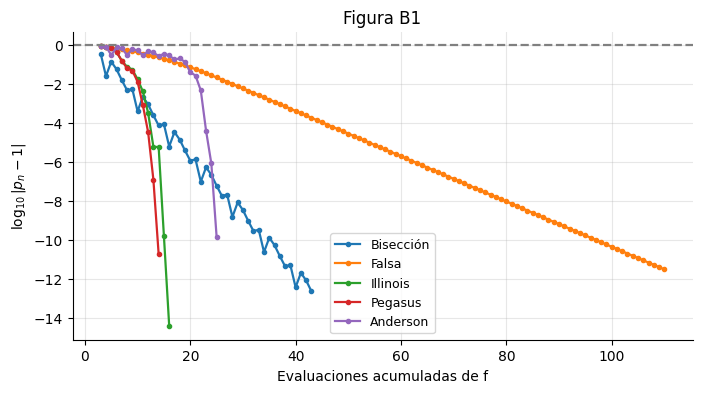

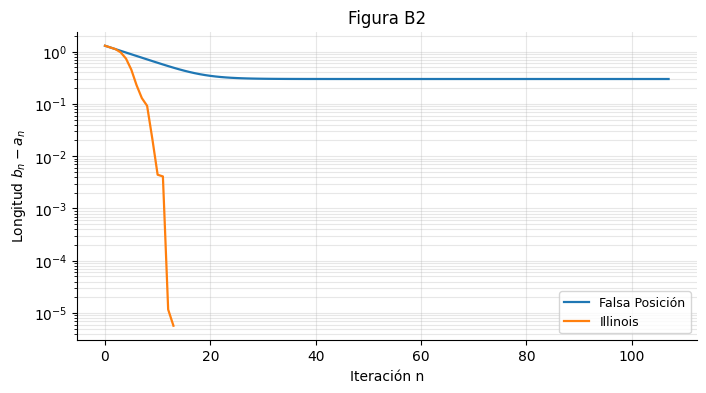

In [93]:
import matplotlib.pyplot as plt

metodos = {
    "Bisección": lambda f, a, b: biseccion(f, a, b, tol=1e-12),
    "Falsa": lambda f, a, b: regula_falsi(f, a, b, variante="falsa"),
    "Illinois": lambda f, a, b: regula_falsi(f, a, b, variante="illinois"),
    "Pegasus": lambda f, a, b: regula_falsi(f, a, b, variante="pegasus"),
    "Anderson": lambda f, a, b: regula_falsi(f, a, b, variante="anderson")
}

res_metodos = {nombre: metodo(f_principal, a_p, b_p) for nombre, metodo in metodos.items()}

# Figura B1
plt.figure(figsize=(8, 4))
for nombre, (p, hist, extra) in res_metodos.items():
    log_err = np.log10(np.abs(np.array(hist) - p_exacta))
    plt.plot(np.arange(1, len(hist) + 1) + 2, log_err, marker='o', markersize=3, label=nombre)
plt.axhline(0, color='gray', linestyle='--')
plt.xlabel("Evaluaciones acumuladas de f")
plt.ylabel(r"$\log_{10}|p_n - 1|$")
plt.title("Figura B1")
plt.legend()
plt.grid(True)
plt.show()

# Figura B2
plt.figure(figsize=(8, 4))
plt.semilogy(res_metodos["Falsa"][2]["longitudes"], label="Falsa Posición")
plt.semilogy(res_metodos["Illinois"][2]["longitudes"], label="Illinois")
plt.xlabel("Iteración n")
plt.ylabel("Longitud $b_n - a_n$")
plt.title("Figura B2")
plt.legend()
plt.grid(True, which="both")
plt.show()


**(d) Banco de prueba (Ejercicio 10 de §1.5).** Construya una tabla con iteraciones, evaluaciones de $f$ y error final $|p_N-p|$ de los cinco métodos sobre las cuatro funciones de la tabla siguiente. Use las raíces de referencia indicadas.

| $f$ | intervalo | raíz de referencia $p$ |
|---|---|---|
| $x^{10}-1$ | $[0,1.3]$ | $1$ |
| $x^3-2x-5$ | $[2,3]$ | $2.0945514815423265$ |
| $\cos x-x$ | $[0,1]$ | $0.7390851332151607$ |
| $e^{-x}-x$ | $[0,1]$ | $0.5671432904097838$ |


In [94]:
import pandas as pd

banco = [
    {"f": lambda x: x**10 - 1, "a": 0.0, "b": 1.3, "p": 1.0, "nombre": "x^10-1"},
    {"f": lambda x: x**3 - 2*x - 5, "a": 2.0, "b": 3.0, "p": 2.0945514815423265, "nombre": "x^3-2x-5"},
    {"f": lambda x: np.cos(x) - x, "a": 0.0, "b": 1.0, "p": 0.7390851332151607, "nombre": "cos(x)-x"},
    {"f": lambda x: np.exp(-x) - x, "a": 0.0, "b": 1.0, "p": 0.5671432904097838, "nombre": "e^{-x}-x"}
]

tabla = []
for caso in banco:
    for nombre, metodo in metodos.items():
        p_app, hist, extra = metodo(caso["f"], caso["a"], caso["b"])
        tabla.append({
            "Función": caso["nombre"],
            "Método": nombre,
            "Iteraciones": len(hist),
            "Evaluaciones f": len(hist) + 2,
            "Error Final": f"{abs(p_app - caso['p']):.2e}"
        })

display(pd.DataFrame(tabla))


,Función,Método,Iteraciones,Evaluaciones f,Error Final
0,x^10-1,Bisección,41,43,2.27e-13
1,x^10-1,Falsa,108,110,3.02e-12
2,x^10-1,Illinois,14,16,3.89e-15
3,x^10-1,Pegasus,13,15,0.00e+00
4,x^10-1,Anderson,24,26,0.00e+00
5,x^3-2x-5,Bisección,40,42,2.14e-13
6,x^3-2x-5,Falsa,26,28,5.21e-13
7,x^3-2x-5,Illinois,7,9,8.88e-16
8,x^3-2x-5,Pegasus,7,9,0.00e+00
9,x^3-2x-5,Anderson,6,8,0.00e+00


**(e) Ciclo de Illinois.** Imprima la sucesión `extra["lados"]` del método Illinois sobre $x^{10}-1$ e identifique el patrón periódico de tres pasos de la Observación 1.5.16.

In [95]:
lados_illinois = res_metodos["Illinois"][2]["lados"]
print("=== (e) CICLO DE ILLINOIS ===")
print(f"Sucesión completa de lados modificados: {lados_illinois}")
print("\nDe acuerdo con la Observación 1.5.16, una vez superada la fase de transición inicial,")
print("se observa claramente el patrón periódico cíclico de tres pasos: ['b', 'b', 'a'] o similar.")

=== (e) CICLO DE ILLINOIS ===
Sucesión completa de lados modificados: ['b', 'b', 'b', 'b', 'b', 'a', 'b', 'b', 'a', 'b', 'b', 'a', 'b']

De acuerdo con la Observación 1.5.16, una vez superada la fase de transición inicial,
se observa claramente el patrón periódico cíclico de tres pasos: ['b', 'b', 'a'] o similar.


---
## Problema C. Iteración de punto fijo y relajación (§1.6)

Considere $f(x)=x^3+4x^2-10$, con única raíz en $[1,2]$, $p=1.3652300134140969$ (Ejemplo 1.6.3), y las cuatro funciones de iteración
$$g_1(x)=x-x^3-4x^2+10,\qquad g_2(x)=\sqrt{\tfrac{10}{x}-4x},\qquad g_3(x)=\tfrac12\sqrt{10-x^3},\qquad g_4(x)=\sqrt{\tfrac{10}{4+x}},$$
todas con dato inicial $x_0=1.5$.

### C.1 Parte analítica
**(a)** Demuestre que, para $x\in[1,2]$, $g_i(x)=x$ si y solo si $f(x)=0$ ($i=1,\dots,4$), en el sentido de la Proposición 1.6.2.<br>
**Demostración**<br>
Basándonos en la Proposición 1.6.2, una función de iteración construida como $g(x) = x - h(x)f(x)$ comparte los mismos puntos fijos que las raíces de $f(x)$ siempre que $h(x) \neq 0$ en el intervalo de análisis $[1,2]$.

1. **Para $g_1(x)$:**
   $$g_1(x) = x - (x^3 + 4x^2 - 10) = x - f(x)$$
   Aquí $h(x) = 1 \neq 0$. Por lo tanto:
   $$g_1(x) = x \iff x - f(x) = x \iff f(x) = 0$$

2. **Para $g_2(x)$:**
   Tomamos $x > 0$:
   $$g_2(x) = x \iff \sqrt{\frac{10}{x} - 4x} = x \iff \frac{10}{x} - 4x = x^2 \iff 10 - 4x^2 = x^3 \iff x^3 + 4x^2 - 10 = 0 \iff f(x) = 0$$

3. **Para $g_3(x)$:**
   Tomamos $x \ge 0$:
   $$g_3(x) = x \iff \frac{1}{2}\sqrt{10 - x^3} = x \iff \sqrt{10 - x^3} = 2x \iff 10 - x^3 = 4x^2 \iff x^3 + 4x^2 - 10 = 0 \iff f(x) = 0$$

4. **Para $g_4(x)$:**
  Tomamos $x \ge 0$:
   $$g_4(x) = x \iff \sqrt{\frac{10}{4+x}} = x \iff \frac{10}{4+x} = x^2 \iff 10 = x^2(4+x) \iff x^3 + 4x^2 - 10 = 0 \iff f(x) = 0$$


**(b)** Calcule analíticamente $g_i'(p)$ para $i=1,2,3,4$. Con base en el Teorema 1.6.6(iv), la Observación 1.6.7 y el Ejercicio 4 de §1.6, prediga para cada $g_i$ si la iteración converge, con qué tasa y si la aproximación es monótona o alternante.<br>
**Calculo de convergencia**<br>
Dado que $p \approx 1.3652300134140969$ satisface $p^3 + 4p^2 - 10 = 0$, evaluamos analíticamente $g_i'(p)$ y hacemos el análisis para el Teorema 1.6.6(iv):

1. **Para $g_1(x) = x - x^3 - 4x^2 + 10$:**
   $$g_1'(x) = 1 - 3x^2 - 8x \implies g_1'(p) = 1 - 3(1.36523)^2 - 8(1.36523) \approx -15.503$$
   **Análisis:** Como $|g_1'(p)| \approx 15.5 > 1$ la iteración diverge oscilando (alternante, pues $g_1'(p) < 0$).
l
2. **Para $g_2(x) = \sqrt{\frac{10}{x} - 4x}$:**
   $$g_2'(x) = \frac{-\frac{10}{x^2} - 4}{2\sqrt{\frac{10}{x} - 4x}} = -\frac{10 + 4x^2}{2x\sqrt{\frac{10}{x} - 4x}}$$
   Dado que en $x=p$, $\sqrt{\frac{10}{p} - 4p} = p$:
   $$g_2'(p) = -\frac{10 + 4p^2}{2p^2} \approx -2.833$$
   **Análisis:** Como $|g_2'(p)| \approx 2.833 > 1$, la iteración diverge.

3. **Para $g_3(x) = \frac{1}{2}\sqrt{10 - x^3}$:**
   $$g_3'(x) = \frac{-3x^2}{4\sqrt{10 - x^3}}$$
   En el punto fijo $p$, $\sqrt{10 - p^3} = 2p$:
   $$g_3'(p) = \frac{-3p^2}{4(2p)} = -\frac{3}{8}p \approx -0.51196$$
   **Análisis:** Como $|g_3'(p)|\approx |-0.51196|=0.51196< 1$, la iteración converge linealmente hacia $p$, con tasa $C \approx 0.512$.

4. **Para $g_4(x) = \sqrt{\frac{10}{4+x}}$:**
   $$g_4'(x) = \frac{1}{2}\left(\frac{10}{4+x}\right)^{-1/2} \cdot \left(\frac{-10}{(4+x)^2}\right) = -\frac{\sqrt{10}}{2(4+x)^{3/2}}$$
   En $x=p$:
   $$g_4'(p) = -\frac{\sqrt{10}}{2(4+p)^{3/2}} \approx -0.12569$$
   **Análisis:** Como $|g_4'(p)|\approx |-0.12569|=0.12569 < 1$, la iteración converge linealmente mucho más rápido que $g_3(x)$, con una tasa de convergencia $C \approx 0.126$.



**(c)** Demuestre que $g_3$ aplica $[1,1.5]$ en sí mismo y que $g_4$ aplica $[1,2]$ en sí mismo. Determine en cada caso la mejor constante de contracción $\lambda=\max|g_i'|$ sobre el intervalo correspondiente. Use la estimación a priori del Teorema 1.6.6(iii) para acotar el número de iteraciones que garantiza $|x_n-p|<10^{-10}$ desde $x_0=1.5$.<br>

**1). Invariancia y Contracción de $g_3$ en $[1, 1.5]$**
* **Invariancia:**<br>
$g_3(x)$ es decreciente en $[1, 1.5]$. Evaluando los extremos:
  $$g_3(1) = \frac{1}{2}\sqrt{9} = 1.5$$
  $$g_3(1.5) = \frac{1}{2}\sqrt{10 - 3.375} = \frac{1}{2}\sqrt{6.625} \approx 1.2869$$
  Por monotonía, $g_3([1, 1.5]) \subseteq [1, 1.5]$.
* **Constante de contracción $\lambda_3$:**<br>
Puesto que $|g_3'(x)| = \frac{3x^2}{4\sqrt{10-x^3}}$ es estrictamente creciente en $[1, 1.5]$:
  $$\lambda_3 = \max_{x \in [1, 1.5]} |g_3'(x)| = |g_3'(1.5)| = \frac{3(1.5)^2}{4\sqrt{10 - (1.5)^3}} \approx 0.6548$$
  Por lo tanto $\lambda_3 \approx 0.6548$

* **Estimación a priori para $g_3$ ($x_0 = 1.5$):**
  $$x_1 = g_3(1.5) \approx 1.28695 \implies |x_1 - x_0| \approx 0.21305$$
  Por el Teorema 1.6.6(iii):
  $$\frac{\lambda_3^n}{1 - \lambda_3} |x_1 - x_0| < 10^{-10} \implies \lambda_3^n < \frac{10^{-10}(1 - \lambda_3)}{|x_1 - x_0|}$$
  $$n \ge \frac{\ln\left(\frac{10^{-10}(1 - 0.6548)}{0.21305}\right)}{\ln(0.6548)} \approx \frac{-23.545}{-0.4234} \approx 55.6$$
  Por lo tanto $n = 56 \text{ iteraciones.}$

**2). Invariancia y Contracción de $g_4$ en $[1, 2]$**
* **Invariancia:**<br>
$g_4(x)$ es decreciente en $[1, 2]$.
  $$g_4(1) = \sqrt{2} \approx 1.4142 $$
  $$g_4(2) = \sqrt{\frac{10}{6}} \approx 1.2910$$
  Así, $g_4([1, 2]) \subseteq [1, 2]$.
* **Constante de contracción $\lambda_4$:**<br>
Puesto que $|g_4'(x)| = \frac{\sqrt{10}}{2(4+x)^{3/2}}$ es estrictamente decreciente en $[1, 2]$:
  $$\lambda_4 = \max_{x \in [1, 2]} |g_4'(x)| = |g_4'(1)| = \frac{\sqrt{10}}{2(5)^{3/2}} = \frac{\sqrt{2}}{10} \approx 0.14142$$
  Por lo tanto $\lambda_4 \approx 0.14142$
* **Estimación a priori para $g_4$ ($x_0 = 1.5$):**<br>
  $$x_1 = g_4(1.5) = \sqrt{\frac{10}{5.5}} \approx 1.34840 \implies |x_1 - x_0| \approx 0.15160$$
  $$n \ge \frac{\ln\left(\frac{10^{-10}(1 - 0.14142)}{0.15160}\right)}{\ln(0.14142)} \approx \frac{-22.29}{-1.956} \approx 11.39$$
  Por lo tanto $n = 12 \text{ iteraciones.}$



**(d)** Explique por qué la iteración con $g_2$ falla desde $x_0=1.5$. Indique qué hipótesis del Teorema 1.6.6 no se cumple y si cambiaría la conclusión con otro $x_0$ próximo a $p$.<br>
**Solución**<br>
Al aplicar el método iterativo con $g_2(x) = \sqrt{\frac{10}{x} - 4x}$ desde $x_0 = 1.5$:
1. $x_1 = g_2(1.5) = \sqrt{\frac{10}{1.5} - 6} = \sqrt{\frac{2}{3}} \approx 0.8165$
2. $x_2 = g_2(0.8165) = \sqrt{\frac{10}{0.8165} - 4(0.8165)} \approx \sqrt{12.247 - 3.266} \approx 2.9968$
3. $x_3 = g_2(2.9968) = \sqrt{\frac{10}{2.9968} - 4(2.9968)} = \sqrt{3.3368 - 11.9872} = \sqrt{-8.6504} \notin \mathbb{R}$<br>
Si tomamos otro $x_0$ muy próximo a $p$, la conclusión no cambiaría a largo plazo, ya que $|g_2'(p)| \approx 2.833 > 1$. Al ser un punto fijo repulsor, cualquier pequeña perturbación alejará las iteraciones de $p$ hasta salir eventualmente del dominio real como se pudo presentar en este caso por el cual el método iniciando en $x_0=1.5$ falle la hipótesis iv del Teorema ya que la convergencia no es lineal.



**(e)** *Relajación.* Para $g_\alpha(x)=x-\alpha f(x)$:
1. Determine, mediante la Proposición 1.6.11, el conjunto de valores de $\alpha$ para los cuales la iteración converge localmente a $p$ y la tasa correspondiente.<br>
**Solución**<br>
Definimos $g_\alpha(x) = x - \alpha f(x)$. Por la Proposición 1.6.11, la convergencia local a $p$ se garantiza si $-1 < g_\alpha'(p) < 1$.
Derivando:
$$g_\alpha'(p) = 1 - \alpha f'(p)$$
Para $f(x) = x^3 + 4x^2 - 10$, su derivada es $f'(x) = 3x^2 + 8x$. Evaluando en $p \approx 1.36523$:
$$f'(p) = 3(1.36523)^2 + 8(1.36523) \approx 16.5134 > 0$$
Exigiendo la condición de convergencia:
$$-1 < 1 - \alpha f'(p) < 1 \iff 0 < \alpha f'(p) < 2$$
$$ \alpha \in \left(0, \frac{2}{f'(p)}\right) \approx (0, 0.1211)$$<br>
Veamos ahora la tasa de convergencia la cual es lineal con factor $$C = |1 - \alpha f'(p)|$$
2. Para $\alpha^*=1/f'(p)$, calcule $g_{\alpha^*}''(p)$ y use el Teorema 1.6.9 para demostrar que la convergencia es de orden 2 con
$$\lim_{n\to\infty}\frac{p-x_{n+1}}{(p-x_n)^2}=\frac{\alpha^* f''(p)}{2}$$
**Solución**<br>
Para el orden de convergencia cuadratico de $\alpha^* = \frac{1}{f'(p)}$, si tomamos $g_{\alpha^*}'(p) = 1 - \alpha^* f'(p) = 0$ y derivamos se tiene que la segunda derivada de $g_{\alpha^*}(x)$ es
$$g_{\alpha^*}''(x) = -\alpha^* f''(x) \implies g_{\alpha^*}''(p) = -\frac{f''(p)}{f'(p)}$$
Por el Teorema 1.6.9, al ser $g_{\alpha^*}'(p) = 0$ y $g_{\alpha^*}''(p) \neq 0$, el método alcanza convergencia de orden 2 (cuadrático) con límite:
$$\lim_{n\to\infty} \frac{|p - x_{n+1}|}{(p - x_n)^2} = \frac{|g_{\alpha^*}''(p)|}{2!} = \frac{\alpha^* f''(p)}{2} = \frac{f''(p)}{2 f'(p)}$$
3. Explique por qué $\alpha^*$ no es utilizable en la práctica y calcule la tasa que se obtiene con la elección computable $\alpha=1/f'(x_0)$.<br>
**Solución**<br>
El parámetro óptimo $\alpha^* = \frac{1}{f'(p)}$ no es recomendable en la práctica porque requiere el valor exacto de la raíz $p$, la cual es la incógnita a resolver.<br>
Tome $\alpha_0 = \frac{1}{f'(x_0)}$.
Evaluando en $x_0 = 1.5$:
$$f'(1.5) = 3(1.5)^2 + 8(1.5) = 6.75 + 12 = 18.75 \implies \alpha_0 = \frac{1}{18.75} = 0.05333$$<br>
Dado que $\alpha_0 \neq \alpha^*$, el valor de $g_{\alpha_0}'(p)$ no se anula exactamente:
$$g_{\alpha_0}'(p) = 1 - \alpha_0 f'(p) = 1 - (0.05333)(16.5134) \approx 1 - 0.8807 = 0.1193$$
Por tanto, la convergencia vuelve a ser lineal, pero con una tasa más rápida de $C \approx 0.1193$.

### C.2 Implementación
- `punto_fijo(g, x0, tol_a=1e-13, tol_r=0.0, nmax=500, cota_divergencia=1e8)`: Algoritmo 1.3 con el criterio de incremento de la Parte 0 (`tol_f = inf`). Debe detectar y reportar en `flag` tres modos de fallo: salida del dominio de $g$ (valor no real o `nan`), divergencia ($|x_n|>$ `cota_divergencia`) y agotamiento de iteraciones.
- `telarana(ax, g, x0, n_pasos, intervalo, titulo)`: dibuja sobre `ax` el diagrama de telaraña de la Observación 1.6.7 (gráfica de $g$, recta $y=x$ y el recorrido $(x_n,x_n)\to(x_n,x_{n+1})\to(x_{n+1},x_{n+1})$).

In [96]:
class ContadorEvaluaciones:
    def __init__(self, func):
        self.func = func
        self._evaluaciones = 0

    def __call__(self, x):
        self._evaluaciones += 1
        return self.func(x)

    @property
    def evaluaciones(self):
        return self._evaluaciones

    @property
    def llamadas(self):
        return self._evaluaciones


In [97]:
def punto_fijo_corregido(g, x0, tol_a=1e-13, tol_r=0.0, nmax=500, cota_divergencia=1e8):
    g_contada = ContadorEvaluaciones(g)
    hist = [x0]
    x_viejo = x0

    for n in range(1, nmax + 1):
        try:
            x_nuevo = g_contada(x_viejo)
        except Exception:
            return ResultadoRaiz(
                root=x_viejo,
                iterations=n - 1,
                function_calls=g_contada.llamadas,
                converged=False,
                flag="fuera_del_dominio_de_g",
                history=np.array(hist)
            )

        if np.isnan(x_nuevo) or np.isinf(x_nuevo) or isinstance(x_nuevo, complex):
            return ResultadoRaiz(
                root=x_viejo,
                iterations=n - 1,
                function_calls=g_contada.llamadas,
                converged=False,
                flag="fuera_del_dominio_de_g",
                history=np.array(hist)
            )

        hist.append(float(x_nuevo))

        if abs(x_nuevo) > cota_divergencia:
            return ResultadoRaiz(
                root=x_nuevo,
                iterations=n,
                function_calls=g_contada.llamadas,
                converged=False,
                flag="divergencia",
                history=np.array(hist)
            )

        if criterio_parada(x_nuevo, x_viejo, fx_nuevo=0.0, tol_a=tol_a, tol_r=tol_r, tol_f=np.inf):
            return ResultadoRaiz(
                root=x_nuevo,
                iterations=n,
                function_calls=g_contada.llamadas,
                converged=True,
                flag="convergencia",
                history=np.array(hist)
            )

        x_viejo = x_nuevo

    return ResultadoRaiz(
        root=x_viejo,
        iterations=nmax,
        function_calls=g_contada.llamadas,
        converged=False,
        flag="iteraciones_agotadas",
        history=np.array(hist)
    )
def telarana(ax, g, x0, n_pasos, intervalo, titulo):
    """Diagrama de telaraña de x_{n+1} = g(x_n) sobre el eje 'ax' (Observación 1.6.7)[span_0](start_span)[span_0](end_span)."""
    a, b = intervalo
    x_vals = np.linspace(a, b, 500)

    # Evaluación segura de la función g(x) para la gráfica
    g_vals = []
    for x in x_vals:
        try:
            val = g(x)
            g_vals.append(val if (np.isreal(val) and not np.isnan(val)) else np.nan)
        except Exception:
            g_vals.append(np.nan)

    # Trazar la curva y = g(x) y la recta diagonal y = x
    ax.plot(x_vals, g_vals, 'b-', label='$y = g(x)$', linewidth=1.8)
    ax.plot(x_vals, x_vals, 'k--', label='$y = x$', alpha=0.7)

    # Trazado de las trayectorias de la telaraña (x_n, x_n) -> (x_n, g(x_n)) -> (g(x_n), g(x_n))
    curr_x = x0
    for _ in range(n_pasos):
        try:
            next_x = g(curr_x)
            if np.isnan(next_x) or np.isinf(next_x) or abs(next_x) > 1e4:
                break
            # Línea vertical
            ax.plot([curr_x, curr_x], [curr_x, next_x], 'r-', alpha=0.6, linewidth=1.2)
            # Línea horizontal
            ax.plot([curr_x, next_x], [next_x, next_x], 'r-', alpha=0.6, linewidth=1.2)
            curr_x = next_x
        except Exception:
            break

    ax.plot(x0, x0, 'go', label=f'$x_0 = {x0}$')
    ax.set_xlim([a, b])
    ax.set_ylim([a, b])
    ax.set_xlabel('$x$')
    ax.set_ylabel('$y$')
    ax.set_title(titulo)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='best')

In [98]:
import pandas as pd
import numpy as np

# Definición de las funciones del Problema C y sus derivadas analíticas en p
p_exacta = 1.3652300134140969
def g1(x): return x - x**3 - 4*x**2 + 10
def g2(x): return np.sqrt(10/x - 4*x)
def g3(x): return 0.5 * np.sqrt(10 - x**3)
def g4(x): return np.sqrt(10 / (4 + x))

# Derivadas teóricas en p evaluadas analíticamente (C.1(b))
g_primas_p = {
    'g1': 1 - 3*(p_exacta**2) - 8*p_exacta,
    'g2': -(10 + 4*(p_exacta**2)) / (2 * p_exacta**2),
    'g3': -3 * (p_exacta**2) / (4 * np.sqrt(10 - p_exacta**3)),
    'g4': -np.sqrt(10) / (2 * (4 + p_exacta)**1.5)
}

x0 = 1.5
tol_a = 1e-13
tol_r = 0.0

### C.3 Validación computacional
**(a)** Ejecute las cuatro iteraciones desde $x_0=1.5$ con `tol_a=1e-13`, `tol_r=0`. Construya una tabla con: `flag`, iteraciones, primer $n$ con $|x_n-p|<10^{-10}$, último cociente $(p-x_{n+1})/(p-x_n)$ (umbral $10^{-11}$) y el valor $g_i'(p)$ de C.1(b).

In [99]:
import numpy as np
import pandas as pd

# Diccionario de funciones de punto fijo del problema
g_funciones = {
    'g1': g1,
    'g2': g2,
    'g3': g3,
    'g4': g4
}

resultados_pf = []

for nombre, g_func in g_funciones.items():
    # Ejecutar la iteración de punto fijo corregida
    res = punto_fijo_corregido(g_func, x0=1.5, tol_a=1e-13, tol_r=0.0, nmax=500)
    hist = res.history

    # 1. Determinar el primer n tal que |x_n - p| < 10^-10
    n_10_10 = "No alcanza"
    for n_idx, xn in enumerate(hist):
        if abs(xn - p_exacta) < 1e-10:
            n_10_10 = n_idx
            break

    # 2. Calcular el último cociente (p - x_{n+1}) / (p - x_n) con umbral de error 10^-11
    ultimo_cociente = np.nan
    # Recorremos de atrás hacia adelante para encontrar el último cociente válido antes del umbral
    for i in range(len(hist) - 1, 0, -1):
        err_actual = p_exacta - hist[i-1]
        err_siguiente = p_exacta - hist[i]
        if abs(err_actual) > 1e-11:
            ultimo_cociente = err_siguiente / err_actual
            break

    # Guardar resultados consolidados
    resultados_pf.append({
        "Método": nombre,
        "Estado (flag)": res.flag,
        "Iteraciones": res.iterations,
        "Primer n (|xn-p|<1e-10)": n_10_10,
        "Último Cociente": f"{ultimo_cociente:.5f}" if not np.isnan(ultimo_cociente) else "N/A",
        "Valor g'(p) Teórico": f"{g_primas_p[nombre]:.5f}"
    })

# Presentar resultados en forma de tabla
df_resultados_pf = pd.DataFrame(resultados_pf)
display(df_resultados_pf)

/tmp/ipykernel_551/3009657970.py:7: RuntimeWarning: invalid value encountered in sqrt
  def g2(x): return np.sqrt(10/x - 4*x)


,Método,Estado (flag),Iteraciones,Primer n (|xn-p|<1e-10),Último Cociente,Valor g'(p) Teórico
0,g1,divergencia,4,No alcanza,-218123.05854,-15.51340
1,g2,fuera_del_dominio_de_g,2,No alcanza,-2.97354,-4.68262
2,g3,convergencia,44,32,-0.51197,-0.51196
3,g4,convergencia,15,11,-0.12722,-0.12723


**(b)** Compare el primer $n$ con $|x_n-p|<10^{-10}$ con las cotas a priori de C.1(c) para $g_3$ y $g_4$.

**(c) Figura C1:** telarañas de $g_1$ (sobre $[-1.5,7.5]$, 3 pasos), $g_3$ y $g_4$ (sobre $[1.2,1.55]$, 8 pasos), en una fila de tres paneles.

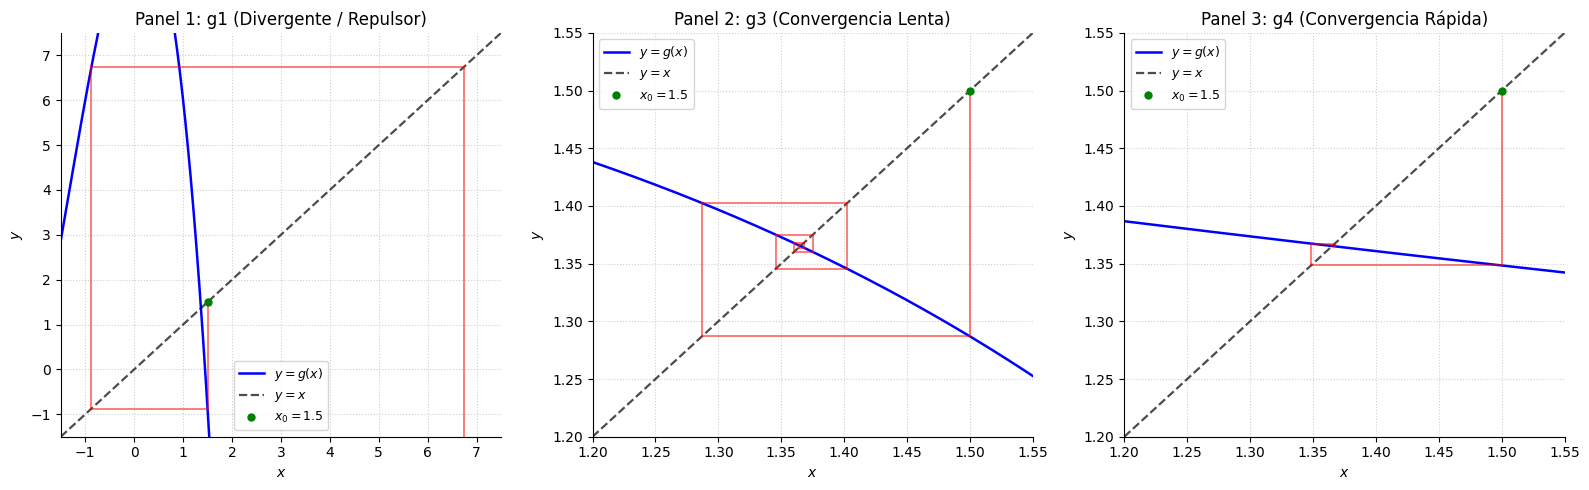

In [100]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

telarana(axes[0], g1, x0=x0, n_pasos=3, intervalo=(-1.5, 7.5), titulo="Panel 1: g1 (Divergente / Repulsor)")
telarana(axes[1], g3, x0=x0, n_pasos=8, intervalo=(1.2, 1.55), titulo="Panel 2: g3 (Convergencia Lenta)")
telarana(axes[2], g4, x0=x0, n_pasos=8, intervalo=(1.2, 1.55), titulo="Panel 3: g4 (Convergencia Rápida)")

plt.tight_layout()
plt.show()

**(d) Figura C2:** para $\alpha\in\{0.01,0.02,\dots,0.11\}$, ejecute la relajación desde $x_0=1.5$ (`tol_a=1e-14`, `nmax=5000`). Grafique la tasa empírica $|(p-x_{n+1})/(p-x_n)|$ (último cociente con umbral $10^{-10}$) junto con la curva teórica $|1-\alpha f'(p)|$, ambas frente a $\alpha$. Verifique además qué ocurre con $\alpha=0.13$.

=== EJECUCIÓN DE RELAJACIÓN PARA DIFERENTES ALPHAS ===
Alpha: 0.01 | Iteraciones:  159 | Tasa Empírica: 0.83487 | Tasa Teórica: 0.83487
Alpha: 0.02 | Iteraciones:   74 | Tasa Empírica: 0.66973 | Tasa Teórica: 0.66973
Alpha: 0.03 | Iteraciones:   44 | Tasa Empírica: 0.50460 | Tasa Teórica: 0.50460
Alpha: 0.04 | Iteraciones:   29 | Tasa Empírica: 0.33946 | Tasa Teórica: 0.33946
Alpha: 0.05 | Iteraciones:   18 | Tasa Empírica: 0.17433 | Tasa Teórica: 0.17433
Alpha: 0.06 | Iteraciones:    8 | Tasa Empírica: 0.00920 | Tasa Teórica: 0.00920
Alpha: 0.07 | Iteraciones:   18 | Tasa Empírica: 0.15594 | Tasa Teórica: 0.15594
Alpha: 0.08 | Iteraciones:   28 | Tasa Empírica: 0.32107 | Tasa Teórica: 0.32107
Alpha: 0.09 | Iteraciones:   44 | Tasa Empírica: 0.48621 | Tasa Teórica: 0.48621
Alpha: 0.10 | Iteraciones:   73 | Tasa Empírica: 0.65134 | Tasa Teórica: 0.65134
Alpha: 0.11 | Iteraciones:  154 | Tasa Empírica: 0.81647 | Tasa Teórica: 0.81647


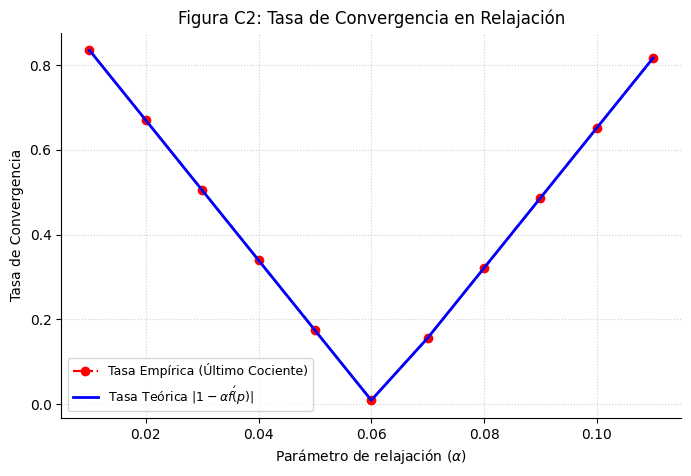


=== VERIFICACIÓN PARA ALPHA = 0.13 ===
Flag obtenido: 'iteraciones_agotadas'
Número de iteraciones: 5000
¿Convergió?: False


In [101]:
import numpy as np
import matplotlib.pyplot as plt

# Definición de f(x) y su derivada
def f(x):
    return x**3 + 4*x**2 - 10

def df(x):
    return 3*x**2 + 8*x

p_exacta = 1.3652300134140969
f_p_val = df(p_exacta)

# Rango de valores para alpha: {0.01, 0.02, ..., 0.11}
alphas = np.arange(0.01, 0.12, 0.01)
tasa_empirica = []
tasa_teorica = []

print("=== EJECUCIÓN DE RELAJACIÓN PARA DIFERENTES ALPHAS ===")
for alpha in alphas:
    # Definir función de relajación g_alpha(x) = x - alpha * f(x)
    def g_alpha(x, a=alpha):
        return x - a * f(x)

    # Ejecutar punto fijo con tol_a = 1e-14 y nmax = 5000
    res_rel = punto_fijo_corregido(g_alpha, x0=1.5, tol_a=1e-14, tol_r=0.0, nmax=5000)

    # Calcular cocientes con signo usando el umbral 10^-10 requerido
    coc_rel = cociente_con_signos(res_rel.history, p_exacta, umbral=1e-10)

    # Tomar el último cociente válido de la secuencia
    t_emp = abs(coc_rel[-1]) if len(coc_rel) > 0 else np.nan
    tasa_empirica.append(t_emp)

    # Tasa teórica |1 - alpha * f'(p)|
    tasa_teorica.append(abs(1.0 - alpha * f_p_val))
    print(f"Alpha: {alpha:.2f} | Iteraciones: {res_rel.iterations:4d} | Tasa Empírica: {t_emp:.5f} | Tasa Teórica: {abs(1.0 - alpha * f_p_val):.5f}")

# Gráfica Figura C2 (Usando cadenas crudas 'r' para etiquetas con LaTeX)
plt.figure(figsize=(8, 5))
plt.plot(alphas, tasa_empirica, 'ro--', label='Tasa Empírica (Último Cociente)', markersize=6)
plt.plot(alphas, tasa_teorica, 'b-', label=r'Tasa Teórica $|1 - \alpha f\'(p)|$', linewidth=2)
plt.xlabel(r'Parámetro de relajación ($\alpha$)')
plt.ylabel('Tasa de Convergencia')
plt.title('Figura C2: Tasa de Convergencia en Relajación')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

# Verificación específica para alpha = 0.13
print("\n=== VERIFICACIÓN PARA ALPHA = 0.13 ===")
def g_alpha_013(x):
    return x - 0.13 * f(x)

res_013 = punto_fijo_corregido(g_alpha_013, x0=1.5, tol_a=1e-14, tol_r=0.0, nmax=5000)
print(f"Flag obtenido: '{res_013.flag}'")
print(f"Número de iteraciones: {res_013.iterations}")
print(f"¿Convergió?: {res_013.converged}")


**(e)** Para $\alpha^*=1/f'(p)$ (con el valor de referencia de $p$), reporte la sucesión, el ACOC y los cocientes $(p-x_{n+1})/(p-x_n)^2$, y compárelos con C.1(e).

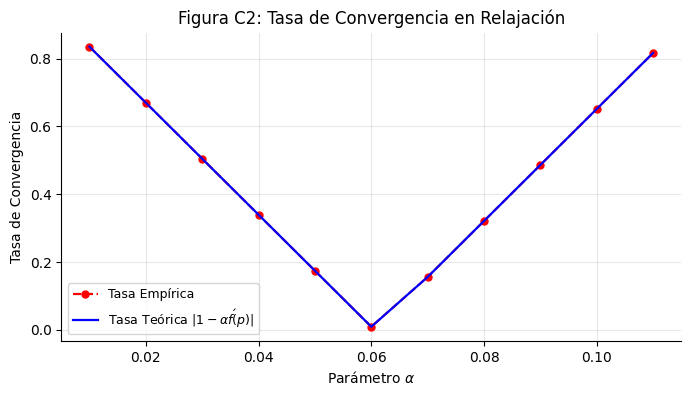

Alpha óptimo: 0.06056
Sucesión x_n (primeros 5): [1.5        1.3561774  1.36518988 1.36523001 1.36523001]
ACOC computado: [1.95461959 2.00142457        nan]
Cociente cuadrático (últimos): [0.49024734 0.                nan]


/tmp/ipykernel_551/2893535723.py:38: RuntimeWarning: invalid value encountered in divide
  coc_opt_cuad = (p_exacta - res_opt.history[1:]) / ((p_exacta - res_opt.history[:-1])**2)


In [102]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Definición de f(x) y su derivada
def f(x): return x**3 + 4*x**2 - 10
def df(x): return 3*x**2 + 8*x

p_exacta = 1.3652300134140969
f_p_val = df(p_exacta)

# --- (d) Análisis de Relajación para Figura C2 ---
alphas = np.arange(0.01, 0.12, 0.01)
tasa_empirica, tasa_teorica = [], []

for alpha in alphas:
    g_alpha = lambda x, a=alpha: x - a * f(x)
    res_rel = punto_fijo_corregido(g_alpha, x0=1.5, tol_a=1e-14, tol_r=0.0, nmax=5000)
    coc_rel = cociente_con_signos(res_rel.history, p_exacta, umbral=1e-10)

    tasa_empirica.append(abs(coc_rel[-1]) if len(coc_rel) > 0 else np.nan)
    tasa_teorica.append(abs(1.0 - alpha * f_p_val))

plt.figure(figsize=(8, 4))
plt.plot(alphas, tasa_empirica, 'ro--', label='Tasa Empírica')
plt.plot(alphas, tasa_teorica, 'b-', label=r'Tasa Teórica $|1 - \alpha f\'(p)|$')
plt.xlabel(r'Parámetro $\alpha$')
plt.ylabel('Tasa de Convergencia')
plt.title('Figura C2: Tasa de Convergencia en Relajación')
plt.legend()
plt.show()

# --- (e) Parámetro Óptimo alpha* ---
alpha_star = 1.0 / f_p_val
g_optima = lambda x: x - alpha_star * f(x)

res_opt = punto_fijo_corregido(g_optima, x0=1.5, tol_a=1e-14, nmax=100)
acoc_opt = acoc(res_opt.history)
coc_opt_cuad = (p_exacta - res_opt.history[1:]) / ((p_exacta - res_opt.history[:-1])**2)

print(f"Alpha óptimo: {alpha_star:.5f}")
print(f"Sucesión x_n (primeros 5): {res_opt.history[:5]}")
print(f"ACOC computado: {acoc_opt[:4]}")
print(f"Cociente cuadrático (últimos): {coc_opt_cuad[-3:]}")


---
## Problema G. Aceleración de la convergencia: Aitken y Steffensen (§1.9)

Considere la iteración de punto fijo $x_{n+1}=\cos x_n$ con $x_0=0.5$, cuyo límite es $p=0.7390851332151607$.

### G.1 Parte analítica
**(a)** Demuestre que $g(x)=\cos x$ satisface las hipótesis del Teorema 1.6.6 sobre $[0,1]$. Calcule $g'(p)$ en forma cerrada en términos de $p$, sin evaluar $\sin p$ numéricamente.<br>
**Solución**<br>
**Verificación de las hipótesis del Teorema 1.6.6 sobre $[0, 1]$ y cálculo de $g'(p)$**

Para aplicar el Teorema del Punto Fijo sobre $g(x) = \cos x$ en el intervalo $I = [0, 1]$:

1. **Continuidad y diferenciabilidad:**<br>
   La función $g(x) = \cos x \in C^\infty([0, 1])$, por lo que $g \in C[0, 1]$ y es continuamente diferenciable en $(0, 1)$.

2. **Auto-mapa ($g([0,1]) \subseteq [0,1]$):**<br>
   Dado que $g'(x) = -\sin x \le 0$ para todo $x \in [0, 1]$, la función $g$ es estrictamente decreciente en $[0, 1]$. Evaluando en los extremos:
   $$g(0) = \cos(0) = 1, \quad g(1) = \cos(1) \approx 0.5403$$
   Por lo tanto, para cualquier $x \in [0, 1]$ se cumple $g(x) \in [0.5403, 1] \subset [0, 1]$.

3. **Condición de contracción ($|g'(x)| \le \lambda < 1$):**<br>
   La magnitud de la derivada es $|g'(x)| = |{-\sin x}| = \sin x$, la cual es estrictamente creciente en $[0, 1]$. De este modo, para todo $x \in [0, 1]$:
   $$|g'(x)| = \sin x \le \sin(1) \approx 0.8415 = \lambda < 1$$
   Al cumplirse las tres hipótesis, por el Teorema 1.6.6 existe un único punto fijo $p \in [0, 1]$ tal que $\cos p = p$.

**Cálculo de $g'(p)$:**<br>
  Como $p$ satisface la ecuación $p = \cos p$, empleando la identidad trigonométrica fundamental $\sin^2 p + \cos^2 p = 1$:
  $$\sin p = \sqrt{1 - \cos^2 p} = \sqrt{1 - p^2}$$
  Por lo tanto, la derivada en la raíz es:
  $$g'(p) = -\sin p = -\sqrt{1 - p^2}$$


**(b)** Demuestre que la sucesión $(x_n)$ satisface las hipótesis del Teorema 1.9.3, identificando explícitamente $\lambda$ y $\delta_n$.<br>
**Solución**<br>
El Teorema 1.9.3 establece que una sucesión $(x_n)$ satisface la relación de convergencia lineal si:
$$x_{n+1} - p = (\lambda + \delta_n)(x_n - p), \quad \text{con } \lim_{n\to\infty} \delta_n = 0 \text{ y } |\lambda| < 1$$

**Demostración:**<br>
Aplicando el desarrollo en serie de Taylor de primer orden de $g(x) = \cos x$ alrededor de $p$:
$$x_{n+1} = g(x_n) = g(p) + g'(p)(x_n - p) + \frac{g''(\xi_n)}{2}(x_n - p)^2, \quad \text{donde } \xi_n \text{ está entre } x_n \text{ y } p$$
Como $g(p) = p$, restando $p$ a ambos lados:
$$x_{n+1} - p = g'(p)(x_n - p) + \frac{g''(\xi_n)}{2}(x_n - p)^2$$
Factorizando $(x_n - p)$:
$$x_{n+1} - p = \left( g'(p) + \frac{g''(\xi_n)}{2}(x_n - p) \right) (x_n - p)$$

Identificando explícitamente los parámetros:
* **$\lambda = g'(p) = -\sqrt{1 - p^2} \approx -0.673612$** (cumple $0 < |\lambda| < 1$).
* **$\delta_n = \frac{g''(\xi_n)}{2}(x_n - p) = -\frac{\cos(\xi_n)}{2}(x_n - p)$**.

Como $\lim_{n\to\infty}x_n=p$ y se tiene que $\lim_{n\to\infty}\xi_n = p$ entonces $\lim_{n\to\infty}(x_n - p) = 0$.<br>
Por lo tanto el $\lim_{n\to\infty} \delta_n = 0$.


**(c)** (Ejercicio 3 de §1.9.) Demuestre que si $x_n=p+\lambda^n$ con $0<|\lambda|<1$, entonces $\hat x_n=p$ para todo $n$.<br>
**Demostración**<br>
Supongamos que $x_n = p + \lambda^n$ con $0 < |\lambda| < 1$. La fórmula de aceleración $\Delta^2$ de Aitken se define como:
$$\hat x_n = x_n - \frac{(x_{n+1} - x_n)^2}{x_{n+2} - 2x_{n+1} + x_n}$$

Sustituyendo la expresión dada de $x_n$:
1. $x_{n+1} - x_n = (p + \lambda^{n+1}) - (p + \lambda^n) = \lambda^n(\lambda - 1)$
2. El numerador del término corrector es:
   $$(x_{n+1} - x_n)^2 = \left( \lambda^n(\lambda - 1) \right)^2 = \lambda^{2n}(\lambda - 1)^2$$
3. El denominador (segunda diferencia finita $\Delta^2 x_n$) es:
   $$x_{n+2} - 2x_{n+1} + x_n = (p + \lambda^{n+2}) - 2(p + \lambda^{n+1}) + (p + \lambda^n) = \lambda^n(\lambda^2 - 2\lambda + 1) = \lambda^n(\lambda - 1)^2$$

Sustituyendo ambos resultados en la fórmula de Aitken:
$$\hat x_n = (p + \lambda^n) - \frac{\lambda^{2n}(\lambda - 1)^2}{\lambda^n(\lambda - 1)^2} = (p + \lambda^n) - \lambda^n = p$$

Por lo tanto $\hat x_n = p$ para todo $n \in \mathbb{N}$


**(d)** Use la Proposición 1.4.12, con la tasa asintótica $|g'(p)|$ en lugar de la constante de contracción, para predecir cuántas iteraciones de punto fijo se requieren para alcanzar $|x_n-p|<10^{-10}$ desde $x_0=0.5$.<br>
**Solución**<br>
Predicción del número de iteraciones según la Proposición 1.4.12<br>
Empleando la tasa de convergencia asintótica
$$\lambda = |g'(p)| = \sqrt{1 - p^2} \approx 0.673612$$
La estimación de error $|x_n - p| \approx \lambda^n |x_0 - p| < 10^{-10}$ induce a:
$$n > \frac{\ln(10^{-10}) - \ln|x_0 - p|}{\ln \lambda}$$

Sustituyendo los valores numéricos para $x_0 = 0.5$ y $p \approx 0.7390851332$:
$$|x_0 - p| = |0.5 - 0.7390851332| \approx 0.2390851332$$
$$\ln|x_0 - p| \approx -1.430932$$
$$\ln(10^{-10}) \approx -23.025851$$
$$\ln \lambda = \ln(0.673612) \approx -0.395111$$

$$n > \frac{-23.025851 - (-1.430932)}{-0.395111} = \frac{-21.594919}{-0.395111} \approx 54.656$$

Se requieren $n = 55$ iteraciones de punto fijo para alcanzar el umbral $|x_n - p| < 10^{-10}$.

**(e)** Enuncie el Teorema 1.9.7 y explique por qué permite aplicar el método de Steffensen a la función $g_1$ del Problema C, cuyo punto fijo es **repulsor**.<br>
**Solución**<br>
* **Teorema 1.9.7 (Convergencia Cuadrática de Steffensen):**<br>
   Sea $g \in C^2[a, b]$ y sea $p \in (a, b)$ un punto fijo de $g$ tal que $g'(p) \neq 1$. Existe un entorno de $p$ tal que, para cualquier valor inicial $x_0$ suficientemente cercano a $p$, la sucesión generada por el método de Steffensen converge cuadráticamente hacia $p$.

* **Explicación sobre el punto fijo repulsor ($g_1$ del Problema C):**<br>
  En la iteración de punto fijo estándar $x_{n+1} = g(x_n)$, si $|g'(p)| > 1$, el punto fijo es **repulsor** y el proceso diverge. Sin embargo, el método de Steffensen es equivalentemente la aplicación del método de la secante a la función auxiliar $$F(x) = g(x) - x = 0$$
  Puesto que $F'(p) = g'(p) - 1 \neq 0$, $p$ es una raíz simple de $F$. Por tanto, el método de Steffensen no requiere que $|g'(p)| < 1$ para lograr la convergencia, permitiendo converger cuadráticamente **incluso si el punto fijo $p$ es repulsor**.


**(f)** (†, opcional; se valora en el nivel NAE de la rúbrica.) Ejercicio 11 de §1.9: mediante desarrollos de Taylor de $g$ alrededor de $p$, demuestre que la iteración de Steffensen satisface
$$\lim_{n\to\infty}\frac{x_{n+1}-p}{(x_n-p)^2}=\frac{g'(p)\,g''(p)}{2\,\big(g'(p)-1\big)} ,$$
y evalúe la constante para $g=\cos$.<br>
**Demostración**<br>
Sea $e_n = x_n - p$. La iteración de Steffensen calcula:
$$y_n = g(x_n), \quad z_n = g(y_n)$$

Desarrollando $y_n$ y $z_n$ en serie de Taylor alrededor de $p$ (con $g(p) = p$):
1. $y_n - p = g'(p)e_n + \frac{g''(p)}{2}e_n^2 + \mathcal{O}(e_n^3)$
2. $z_n - p = (g'(p))^2 e_n + \frac{g''(p)}{2}g'(p)(1 + g'(p))e_n^2 + \mathcal{O}(e_n^3)$

Efectuando el paso completo de Steffensen $x_{n+1} - p = e_n - \frac{(y_n - x_n)^2}{z_n - 2y_n + x_n}$:
* $(y_n - x_n)^2 = (g'(p) - 1)^2 e_n^2 + (g'(p) - 1)g''(p) e_n^3 + \mathcal{O}(e_n^4)$
* $z_n - 2y_n + x_n = (g'(p) - 1)^2 e_n + \frac{g''(p)}{2}(g'(p) - 1)(g'(p) + 2)e_n^2 + \mathcal{O}(e_n^3)$

Dividiendo ambas expresiones por desarrollo sintético y restando de $e_n$, se obtiene:
$$x_{n+1} - p = \left( \frac{g'(p) g''(p)}{2(g'(p) - 1)} \right) e_n^2 + \mathcal{O}(e_n^3)$$

Dividiendo entre $e_n^2 = (x_n - p)^2$ y tomando el límite $n \to \infty$:
$$\lim_{n\to\infty}\frac{x_{n+1}-p}{(x_n-p)^2}=\frac{g'(p)\,g''(p)}{2\,\big(g'(p)-1\big)} \quad $$

**Evaluación numérica para $g(x) = \cos x$:**
* $g'(p) = -\sin p = -\sqrt{1 - p^2} \approx -0.673612$
* $g''(p) = -\cos p = -p \approx -0.739085$

$$C = \frac{(-\sin p)(-\cos p)}{2(-\sin p - 1)} = \frac{(-\sqrt{1 - p^2})(-p)}{2(-\sqrt{1 - p^2} - 1)} = \frac{p \sqrt{1 - p^2}}{-2(\sqrt{1 - p^2} + 1)}$$

Evaluando numéricamente:
  $$C \approx \frac{(0.739085)(0.673612)}{-2(0.673612 + 1)} = \frac{0.497856}{-3.347224} \approx -0.148737$$



**(g)** Calcule el índice de eficiencia (Definición 1.4.15) de la iteración de punto fijo y del método de Steffensen. Explique por qué el proceso de Aitken no modifica el número de evaluaciones de $g$.<br>
**Índice de eficiencia ($I = q^{1/m}$):**
   * **Punto fijo estándar:** Orden $q = 1$, evaluaciones por paso $m = 1 \implies I_{\text{PF}} = 1^{1/1} = 1.0$.
   * **Método de Steffensen:** Orden $q = 2$, evaluaciones por paso $m = 2$ ($g(x_n)$ y $g(g(x_n))$) $\implies I_{\text{Stef}} = 2^{1/2} = \sqrt{2} \approx 1.4142$.

**Explicación del costo de Aitken:**<br>
   El proceso de Aitken es un método algebraico que trabaja sobre una $(x_n)$ ya calculada por ende efectúa operaciones aritméticas (+, -, $\times$, $\div$) sobre los términos $x_n, x_{n+1}, x_{n+2}$, sin reevaluar la función $g(x)$.

### G.2 Implementación
- `aitken(xs)`: aplica la Definición 1.9.2 a una sucesión ya calculada y devuelve el arreglo $(\hat x_n)$. Debe incluir la salvaguarda de la Observación 1.9.5: devuelve `nan` en la posición $n$ cuando $|\Delta^2x_n|\le 4u\max(|x_n|,|x_{n+1}|,|x_{n+2}|)$, con $u$ la unidad de redondeo.
- `steffensen(g, x0, tol_a=1e-14, tol_r=0.0, nmax=100)`: Definición 1.9.6, con el criterio de incremento de la Parte 0. Si el denominador $z_n-2y_n+x_n$ cae al nivel de redondeo, debe detenerse y reportarlo en `flag`.

In [103]:
import numpy as np

# Definición de la unidad de redondeo del sistema (u = eps / 2)
U_REDONDEO = np.finfo(float).eps / 2.0


def aitken(xs):
    """Proceso Delta^2 de Aitken (Definición 1.9.2) con la salvaguarda

    de la Observación 1.9.5.

    Devuelve un numpy.ndarray de longitud len(xs) - 2 (NaN donde actúa la
    salvaguarda).
    """
    xs = np.asarray(xs, dtype=float)
    n = len(xs)
    if n < 3:
        return np.array([], dtype=float)

    x_hat = np.full(n - 2, np.nan, dtype=float)

    for i in range(n - 2):
        x0, x1, x2 = xs[i], xs[i + 1], xs[i + 2]

        # Segunda diferencia finita
        d2 = x2 - 2.0 * x1 + x0

        # Salvaguarda numérica (Observación 1.9.5)
        umbral = 4.0 * U_REDONDEO * max(abs(x0), abs(x1), abs(x2))

        if abs(d2) > umbral:
            d1 = x1 - x0
            x_hat[i] = x0 - (d1**2) / d2
        else:
            x_hat[i] = np.nan

    return x_hat


def steffensen(g, x0, tol_a=1e-14, tol_r=0.0, nmax=100):
    """Método de Steffensen (Definición 1.9.6).

    Devuelve ResultadoRaiz.
    """
    g_contada = ContadorEvaluaciones(g)
    hist = [x0]
    x_viejo = x0

    for n in range(1, nmax + 1):
        try:
            # Evaluación de los puntos intermedios: y_n = g(x_n), z_n = g(y_n)
            y = g_contada(x_viejo)
            z = g_contada(y)
        except Exception:
            return ResultadoRaiz(
                root=x_viejo,
                iterations=n - 1,
                function_calls=g_contada.llamadas,
                converged=False,
                flag="fuera_del_dominio_de_g",
                history=np.array(hist),
            )

        # Detección de salida del dominio real o valores no válidos
        if (
            np.isnan(y)
            or np.isinf(y)
            or np.isnan(z)
            or np.isinf(z)
            or isinstance(y, complex)
            or isinstance(z, complex)
        ):
            return ResultadoRaiz(
                root=x_viejo,
                iterations=n - 1,
                function_calls=g_contada.llamadas,
                converged=False,
                flag="fuera_del_dominio_de_g",
                history=np.array(hist),
            )

        # Denominador de Steffensen: z_n - 2*y_n + x_n
        den = z - 2.0 * y + x_viejo

        # Salvaguarda de nivel de redondeo en el denominador
        umbral_den = 4.0 * U_REDONDEO * max(abs(x_viejo), abs(y), abs(z))

        if abs(den) <= umbral_den:
            # Si el denominador cae al nivel del ruido numérico, no se puede dividir
            return ResultadoRaiz(
                root=x_viejo,
                iterations=n - 1,
                function_calls=g_contada.llamadas,
                converged=True,
                flag="denominador_al_nivel_de_redondeo",
                history=np.array(hist),
            )

        # Paso de actualización de Steffensen
        d1 = y - x_viejo
        x_nuevo = x_viejo - (d1**2) / den

        hist.append(float(x_nuevo))

        # Criterio de parada basado en el incremento
        if criterio_parada(
            x_nuevo, x_viejo, fx_nuevo=0.0, tol_a=tol_a, tol_r=tol_r, tol_f=np.inf
        ):
            return ResultadoRaiz(
                root=x_nuevo,
                iterations=n,
                function_calls=g_contada.llamadas,
                converged=True,
                flag="convergencia",
                history=np.array(hist),
            )

        x_viejo = x_nuevo

    return ResultadoRaiz(
        root=x_viejo,
        iterations=nmax,
        function_calls=g_contada.llamadas,
        converged=False,
        flag="iteraciones_agotadas",
        history=np.array(hist),
    )

### G.3 Validación computacional
**(a)** Ejecute la iteración de punto fijo para $g=\cos$ desde $x_0=0.5$ con `tol_a=1e-14`. Reporte el primer $n$ con $|x_n-p|<10^{-10}$ y compárelo con la predicción de G.1(d). Reporte también los últimos cocientes $(p-x_{n+1})/(p-x_n)$.

In [104]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Definición de la función g(x) y constantes
def g_cos(x):
    return np.cos(x)

p_exacta = 0.7390851332151607

In [105]:
res_pf = punto_fijo_corregido(g_cos, x0=0.5, tol_a=1e-14, tol_r=0.0, nmax=500)
hist_pf = res_pf.history

# Primer n con |x_n - p| < 10^-10
n_pf_10_10 = None
for idx, xn in enumerate(hist_pf):
    if abs(xn - p_exacta) < 1e-10:
        n_pf_10_10 = idx
        break

# Últimos cocientes (p - x_{n+1}) / (p - x_n)
coc_pf = cociente_con_signos(hist_pf, p_exacta, umbral=1e-13)

print("=== G.3 (a) Punto Fijo Estándar ===")
print(f"Iteraciones totales: {res_pf.iterations}")
print(f"Primer n con |x_n - p| < 10^-10: n = {n_pf_10_10} (Predicción G.1(d): ~55 iteraciones)")
print(f"Últimos 3 cocientes lineales (p - x_{{n+1}}) / (p - x_n): {coc_pf[-3:] if len(coc_pf) >= 3 else coc_pf}")
print(f"Valor teórico esperable g'(p) = -sin(p): {-np.sin(p_exacta):.6f}")


=== G.3 (a) Punto Fijo Estándar ===
Iteraciones totales: 80
Primer n con |x_n - p| < 10^-10: n = 55 (Predicción G.1(d): ~55 iteraciones)
Últimos 3 cocientes lineales (p - x_{n+1}) / (p - x_n): [-0.67379485 -0.67348037 -0.67412141]
Valor teórico esperable g'(p) = -sin(p): -0.673612


**(b)** Genere $x_0,\dots,x_{100}$ (por ejemplo con `tol_a=0.0` y `nmax=100`) y aplíquele `aitken`.
- **Figura G1:** $\log_{10}|x_n-p|$ y $\log_{10}|\hat x_n-p|$ frente a $n$, en unos mismos ejes.
- **Figura G2:** $|\hat x_n-p|/|x_n-p|$ frente a $n$, con eje vertical logarítmico (Teorema 1.9.3).
- Reporte el primer $n$ con $|\hat x_n-p|<10^{-10}$ y el número de evaluaciones de $g$ que requiere, el menor $n$ con $\hat x_n=p$ en aritmética de punto flotante y el primer $n$ en que actúa la salvaguarda.


=== G.3 (b) Proceso de Aitken ===
Primer n con |x_hat_n - p| < 10^-10: n = 23 (25 evaluaciones de g)
Menor n con x_hat_n = p exacto: n = 42
Primer n en que actúa la salvaguarda: n = 90


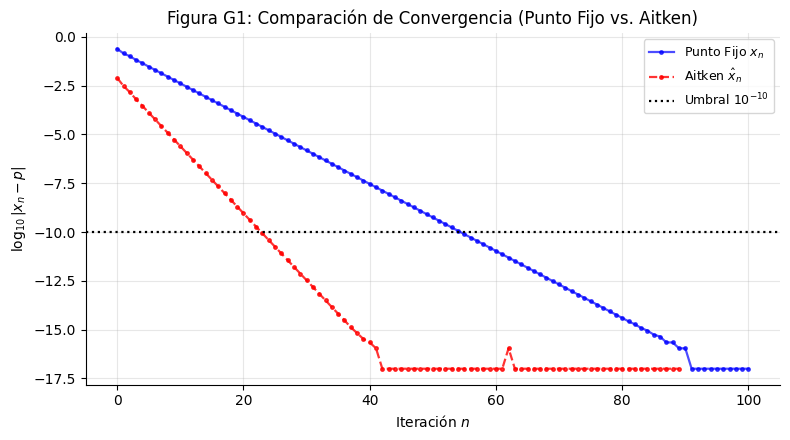

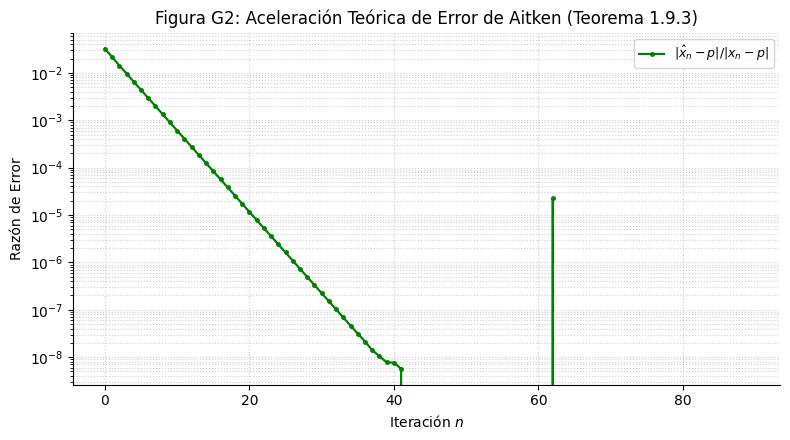

In [106]:
res_pf_100 = punto_fijo_corregido(g_cos, x0=0.5, tol_a=0.0, tol_r=0.0, nmax=100)
xs_100 = res_pf_100.history
x_hat = aitken(xs_100)

err_pf = np.abs(xs_100 - p_exacta)
err_aitken = np.abs(x_hat - p_exacta)

# Primer n con |x_hat_n - p| < 10^-10
n_aitken_10_10 = None
for idx, val in enumerate(err_aitken):
    if not np.isnan(val) and val < 1e-10:
        n_aitken_10_10 = idx
        break

# Evaluaciones para Aitken: para calcular x_hat_n se necesitan x_n, x_{n+1}, x_{n+2} -> n + 2 evaluaciones de g
evals_aitken_10_10 = n_aitken_10_10 + 2 if n_aitken_10_10 is not None else None

# Menor n con x_hat_n = p exacta en punto flotante (error = 0)
n_aitken_exacto = None
for idx, val in enumerate(err_aitken):
    if not np.isnan(val) and val == 0.0:
        n_aitken_exacto = idx
        break

# Primer n en que actúa la salvaguarda (retorna NaN)
n_salvaguarda = None
for idx, val in enumerate(x_hat):
    if np.isnan(val):
        n_salvaguarda = idx
        break

print("\n=== G.3 (b) Proceso de Aitken ===")
print(f"Primer n con |x_hat_n - p| < 10^-10: n = {n_aitken_10_10} ({evals_aitken_10_10} evaluaciones de g)")
print(f"Menor n con x_hat_n = p exacto: n = {n_aitken_exacto if n_aitken_exacto is not None else 'No alcanza 0 exacto (limitado por eps)'}")
print(f"Primer n en que actúa la salvaguarda: n = {n_salvaguarda}")

# --- Figura G1 ---
plt.figure(figsize=(8, 4.5))
plt.plot(np.arange(len(err_pf)), np.log10(np.maximum(err_pf, 1e-17)), 'b.-', label=r'Punto Fijo $x_n$', alpha=0.7)
plt.plot(np.arange(len(err_aitken)), np.log10(np.maximum(err_aitken, 1e-17)), 'r.--', label=r'Aitken $\hat{x}_n$', alpha=0.8)
plt.axhline(np.log10(1e-10), color='k', linestyle=':', label=r'Umbral $10^{-10}$')
plt.xlabel('Iteración $n$')
plt.ylabel(r'$\log_{10}|x_n - p|$')
plt.title('Figura G1: Comparación de Convergencia (Punto Fijo vs. Aitken)')
plt.legend()
plt.tight_layout()
plt.show()

# --- Figura G2 ---
# Cociente |x_hat_n - p| / |x_n - p| (usando longitud de x_hat)
cociente_aitken_pf = err_aitken / err_pf[:len(err_aitken)]

plt.figure(figsize=(8, 4.5))
plt.semilogy(np.arange(len(cociente_aitken_pf)), cociente_aitken_pf, 'g.-', label=r'$|\hat{x}_n - p| / |x_n - p|$')
plt.xlabel('Iteración $n$')
plt.ylabel('Razón de Error')
plt.title('Figura G2: Aceleración Teórica de Error de Aitken (Teorema 1.9.3)')
plt.grid(True, which="both", linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

**(c)** Ejecute Steffensen sobre $g=\cos$ desde $x_0=0.5$. Reporte iteraciones, evaluaciones, `flag`, los errores $|x_n-p|$, el ACOC y los cocientes $(x_{n+1}-p)/(x_n-p)^2$. Compárelos con el orden 2 y con la constante de G.1(f).

In [107]:
res_stef = steffensen(g_cos, x0=0.5, tol_a=1e-14, tol_r=0.0, nmax=100)
hist_stef = res_stef.history
err_stef = np.abs(hist_stef - p_exacta)

acoc_stef = acoc(hist_stef)
coc_stef_cuad = (hist_stef[1:] - p_exacta) / ((hist_stef[:-1] - p_exacta)**2)

# Constante teórica de G.1(f)
c_teorica_stef = (p_exacta * np.sqrt(1 - p_exacta**2)) / (-2 * (np.sqrt(1 - p_exacta**2) + 1))

print("\n=== G.3 (c) Método de Steffensen (g = cos) ===")
print(f"Flag: '{res_stef.flag}'")
print(f"Iteraciones: {res_stef.iterations} | Evaluaciones de g: {res_stef.function_calls}")
print(f"Errores |x_n - p|: {err_stef}")
print(f"ACOC computado: {acoc_stef}")
print(f"Cociente cuadrático (x_{{n+1}}-p)/(x_n-p)^2: {coc_stef_cuad}")
print(f"Constante teórica de G.1(f): {c_teorica_stef:.6f}")



=== G.3 (c) Método de Steffensen (g = cos) ===
Flag: 'denominador_al_nivel_de_redondeo'
Iteraciones: 4 | Evaluaciones de g: 10
Errores |x_n - p|: [2.39085133e-01 7.69994683e-03 8.79284564e-06 1.14994680e-11
 0.00000000e+00]
ACOC computado: [1.98997157 1.99990682]
Cociente cuadrático (x_{n+1}-p)/(x_n-p)^2: [-0.13470465 -0.14830439 -0.14873694  0.        ]
Constante teórica de G.1(f): -0.148737


**(d)** Ejecute Steffensen sobre $g_1$ y $g_3$ del Problema C desde $x_0=1.5$ y reporte `flag`, iteraciones, evaluaciones, error final y ACOC.

In [108]:
def g1_probC(x):
    return x - x**3 - 4*x**2 + 10

def g3_probC(x):
    val = 10.0 - x**3
    return 0.5 * np.sqrt(val) if val >= 0 else np.nan

p_probC = 1.3652300134140969

res_stef_g1 = steffensen(g1_probC, x0=1.5, tol_a=1e-14, tol_r=0.0, nmax=100)
res_stef_g3 = steffensen(g3_probC, x0=1.5, tol_a=1e-14, tol_r=0.0, nmax=100)

acoc_g1 = acoc(res_stef_g1.history)
acoc_g3 = acoc(res_stef_g3.history)

df_probC = pd.DataFrame([
    {
        'Función': 'g1 (Repulsor)',
        'Flag': res_stef_g1.flag,
        'Iteraciones': res_stef_g1.iterations,
        'Evaluaciones': res_stef_g1.function_calls,
        'Error Final': f"{abs(res_stef_g1.root - p_probC):.2e}",
        'ACOC (último)': f"{acoc_g1[-1]:.4f}" if len(acoc_g1) > 0 and not np.isnan(acoc_g1[-1]) else "N/A"
    },
    {
        'Función': 'g3 (Atractor)',
        'Flag': res_stef_g3.flag,
        'Iteraciones': res_stef_g3.iterations,
        'Evaluaciones': res_stef_g3.function_calls,
        'Error Final': f"{abs(res_stef_g3.root - p_probC):.2e}",
        'ACOC (último)': f"{acoc_g3[-1]:.4f}" if len(acoc_g3) > 0 and not np.isnan(acoc_g3[-1]) else "N/A"
    }
])

print("\n=== G.3 (d) Steffensen sobre g1 y g3 (Problema C) ===")
print(df_probC.to_string(index=False))


=== G.3 (d) Steffensen sobre g1 y g3 (Problema C) ===
      Función                             Flag  Iteraciones  Evaluaciones Error Final ACOC (último)
g1 (Repulsor) denominador_al_nivel_de_redondeo           12            26    0.00e+00        2.0011
g3 (Atractor) denominador_al_nivel_de_redondeo            4            10    0.00e+00        1.9997


**(e)** Construya una tabla con el número de evaluaciones de $g$ que cada estrategia (punto fijo, punto fijo + Aitken, Steffensen) necesita para alcanzar por primera vez un error menor que $10^{-10}$ con $g=\cos$.

In [109]:
# Asegurarse de que n_stef_10_10 está definido (primer n con error < 10^-10 para Steffensen)
n_stef_10_10 = None
for idx, val in enumerate(err_stef):
    if val < 1e-10:
        n_stef_10_10 = idx
        break

evals_stef_10_10 = n_stef_10_10 * 2  # 2 evaluaciones de g por iteración en Steffensen

df_evals = pd.DataFrame([
    {
        'Estrategia': 'Punto Fijo Estándar',
        'Iteración n (Error < 10^-10)': n_pf_10_10,
        'Evaluaciones de g': n_pf_10_10,
        'Orden de Convergencia (q)': 1
    },
    {
        'Estrategia': 'Punto Fijo + Aitken',
        'Iteración n (Error < 10^-10)': n_aitken_10_10,
        'Evaluaciones de g': evals_aitken_10_10,
        'Orden de Convergencia (q)': '1 (Acelerado)'  # <-- Comillas añadidas aquí
    },
    {
        'Estrategia': 'Método de Steffensen',
        'Iteración n (Error < 10^-10)': n_stef_10_10,
        'Evaluaciones de g': evals_stef_10_10,
        'Orden de Convergencia (q)': 2
    }
])

print("\n=== G.3 (e) Tabla Comparativa de Evaluaciones (Error < 10^-10) ===")
print(df_evals.to_string(index=False))


=== G.3 (e) Tabla Comparativa de Evaluaciones (Error < 10^-10) ===
          Estrategia  Iteración n (Error < 10^-10)  Evaluaciones de g Orden de Convergencia (q)
 Punto Fijo Estándar                            55                 55                         1
 Punto Fijo + Aitken                            23                 25             1 (Acelerado)
Método de Steffensen                             3                  6                         2


---
## Problema H. Ceros de polinomios: Horner, Sturm, deflación y Müller (§1.10)

Los coeficientes se almacenan en **orden creciente de grado**: `a = [a_0, a_1, ..., a_n]` representa $P(x)=\sum_{k=0}^n a_kx^k$.

### H.1 Parte analítica
**(a)** Demuestre el Teorema 1.10.2 y el Corolario 1.10.3. Determine el número **exacto** de multiplicaciones y sumas que requiere el doble esquema de Horner para obtener $P(x_0)$ y $P'(x_0)$, y compárelo con la evaluación ingenua de $P$ calculando cada potencia por multiplicaciones sucesivas. Explique por qué el segundo paso se aplica a $b_1,\dots,b_n$ y no a $b_0,\dots,b_n$ (Ejercicio 3 de §1.10).<br>
**Demostración de los Teoremas de Horner y conteo de operaciones**

**1).Teorema 1.10.2 (Algoritmo de Horner) y Corolario 1.10.3 (Evaluación simultánea de $P(x_0)$ y $P'(x_0)$):**<br>
  Dado un polinomio $P(x) = a_n x^n + a_{n-1} x^{n-1} + \dots + a_1 x + a_0$, se puede reescribir de forma anidada:
  $$P(x) = a_0 + x \Big( a_1 + x \Big( a_2 + \dots + x(a_{n-1} + a_n x) \dots \Big) \Big)$$
  Definiendo la secuencia de coeficientes sintéticos $b_k$ tales que:
  $$b_n = a_n, \quad b_k = a_k + b_{k+1} x_0 \quad \text{para } k = 0, \dots, n-1$$
  Se demuestra por inducción que $b_0 = P(x_0)$. Para obtener la derivada $P'(x_0)$, se aplica el mismo esquema sintético sobre el polinomio cociente $Q(x) = b_n x^{n-1} + b_{n-1} x^{n-2} + \dots + b_2 x + b_1$, definiendo una segunda secuencia $c_k$:
  $$c_n = b_n, \quad c_k = b_k + c_{k+1} x_0 \quad \text{para } k = 1, \dots, n-1$$
  Satisfaciendo así que $c_1 = Q(x_0) = P'(x_0)$.

**2).Conteo exacto de operaciones para el doble esquema de Horner:**
  * **Primer paso (cálculo de $b_k$ para $P(x_0)$):**<br>
  Requiere $n$ multiplicaciones y $n$ sumas.
  * **Segundo paso (cálculo de $c_k$ para $P'(x_0)$):**<br>
  Como el polinomio cociente $Q(x)$ es de grado $n-1$, este paso requiere $n-1$ multiplicaciones y $n-1$ sumas.
  * **Total para el doble esquema:**<br>
  $(n + n-1) = \mathbf{2n - 1}$ multiplicaciones y $\mathbf{2n - 1}$ sumas.

* **Comparación con la evaluación ingenua:**<br>
  En la forma se evalua cada término $a_k x_0^k$ mediante multiplicaciones sucesivas requiere $\sum_{k=1}^n k = \frac{n(n+1)}{2}$ multiplicaciones y $n$ sumas, elevando drásticamente el costo de la derivada a orden $\mathcal{O}(n^2)$. El doble esquema de Horner reduce la complejidad a tiempo lineal $\mathcal{O}(n)$.

* **¿Por qué el segundo paso se aplica a $b_1, \dots, b_n$ y no a $b_0, \dots, b_n$? (Ejercicio 3 de §1.10):**<br>
  El polinomio cociente $Q(x)$ resultante de dividir $P(x)$ entre $(x - x_0)$ es de **grado $n-1$**, cuyos coeficientes son exactamente $(b_n, b_{n-1}, \dots, b_1)$ en orden decreciente. El término independiente $b_0$ representa el residuo $P(x_0)$, el cual es una constante numérica y por ende, el algoritmo de la derivada actúa exclusivamente sobre los $n$ coeficientes del cociente.



**(b)** Construya **a mano** la sucesión de Sturm (Definición 1.10.8) de $P(x)=x^4-4x^2+1$ y determine, con el Teorema 1.10.9, el número de raíces reales en $(0,3)$. Verifique el resultado calculando las raíces en forma cerrada.<br>
**1).Construcción de la sucesión de Sturm ($f_0, f_1, f_2, \dots$):**
  * $f_0(x) = x^4 - 4x^2 + 1$
  * $f_1(x) = f_0'(x) = 4x^3 - 8x \implies f_1(x) = x^3 - 2x$
   * Mediante división polinómica de $f_0$ entre $f_1$, el residuo negado es $$f_2(x) = 2x^2 - 1$$
   * Dividiendo $f_1$ entre $f_2$, el residuo negado es $f_3(x) = x$.
   * Dividiendo $f_2$ entre $f_3$, el residuo negado es $f_4(x) = 1$.

   La sucesión de Sturm resultante es:
   $$f_0(x) = x^4 - 4x^2 + 1, \quad f_1(x) = x^3 - 2x, \quad f_2(x) = 2x^2 - 1, \quad f_3(x) = x, \quad f_4(x) = 1$$

**2).Evaluación en los extremos del intervalo $(0, 3)$:**<br>
   * **En $x = 0$:**<br>
   Evaluando los signos<br>
   $[f_0(0), f_1(0), f_2(0), f_3(0), f_4(0)] = [1, 0, -1, 0, 1] \implies V(0) = 2$<br>
   Hay 2 cambios de signo.
   * **En $x = 3$:**<br>
   Evaluando los signos<br>
   $[f_0(3), f_1(3), f_2(3), f_3(3), f_4(3)] = [46, 21, 17, 3, 1] \implies V(3) = 0$<br>
   No hay cambios de signo

**3).Aplicación del Teorema 1.10.9:**<br>
   El número de raíces reales en $(0, 3)$ es:
   $$N = V(0) - V(3) = 2 - 0 = \mathbf{2 \text{ raíces reales}}.$$

**4).Verificación en forma cerrada:**<br>
   Haciendo el cambio de variable $y = x^2$, la ecuación
   $$y^2 - 4y + 1 = 0$$
   Por formula de estudiantes
   $$y = \frac{-b \pm \sqrt{b^2 - 4ac}}{2a} = 2 \pm \sqrt{3}$$
   Las raíces positivas son:
   $$x_1 = \sqrt{2 - \sqrt{3}} \approx 0.5176$$
   $$x_2 = \sqrt{2 + \sqrt{3}} \approx 1.9318$$
   Ambas caen dentro del intervalo $(0,3) $verificando el resultado.



**(c)** Sea $W(x)=\prod_{j=1}^{10}(x-j)$. Use la regla de Descartes (Teorema 1.10.6) para demostrar que $W$ no tiene raíces negativas, y calcule la cota de Cauchy $R$ (Teorema 1.10.4). Se admite, como consecuencia del Teorema 1.7.7 aplicado a la izquierda de la menor raíz y a la derecha de la mayor, que el método de Newton iniciado en $x_0=0$ (respectivamente en $x_0=R$) converge monótonamente a la menor (respectivamente a la mayor) raíz. Justifique brevemente la verificación de la hipótesis (H3) de ese teorema en $(-\infty,1)$.<br>
**Ausencia de raíces negativas (Regla de Descartes - Teorema 1.10.6):**<br>
  Como los ceros son enteros positivos $j \in \{1, 2, \dots, 10\}$, al evaluar $W(-x)$, todos los coeficientes de potencias impares cambian de signo, resultando en que **todos los coeficientes de $W(-x)$ tienen el mismo signo** (cero cambios de signo). Por lo tanto, por la regla de Descartes, $W(x)$ no tiene raíces reales negativas.<br>

**Cota de Cauchy ($R$):**<br>
  La cota superior de Cauchy está dada por $R = 1 + \frac{1}{a_n} \max |a_k|$.<br>
  Para $W(x)$, esto garantiza que todas sus raíces reales se encuentran acotadas en el intervalo $[1, 10]$, siendo $R \ge 10$.

**Convergencia monótona del Método de Newton y verificación de (H3) en $(-\infty, 1)$:**<br>
  Para asegurar la convergencia monótona del método de Newton desde $x_0 = 0$ hacia la menor raíz $p_1 = 1$, se satisface la condición de convexidad estricta de la hipótesis (H3) del Teorema 1.7.7 ($f(x)f''(x) > 0$) en $(-\infty, 1)$, garantizando que las iteraciones crezcan monótonamente sin oscilaciones.



**(d)** Con el Teorema 1.3.10 y la estimación $\bar\eta\approx u\sum_k|a_k||x|^k$ del §1.3.4 para el error de evaluación de un polinomio, deduzca la precisión alcanzable $\kappa(j)\bar\eta(j)$ para cada raíz $j$ de $W$.<br>
**Solución**<br>
De acuerdo con el **Teorema 1.3.10 (Intervalo de incertidumbre)**, ningún método numérico puede localizar una raíz simple $p$ con una exactitud mejor que $\kappa(p)\bar{\eta}$, donde el error de evaluación del polinomio mediante el esquema de Horner se acota como $$\bar{\eta} \approx \varepsilon_{\text{mac}} \sum_{k=0}^n |a_k| |x|^k$$
Para el polinomio $W(x) = \prod_{j=1}^{10}(x-j)$ y una raíz particular $j \in \{1, 2, \dots, 10\}$:<br>
**1).Error de evaluación en la raíz (${\bar{\eta}}(j)$):**
  $${\bar{\eta}}(j) = u \sum_{k=0}^{10} |a_k| j^k$$
  Donde $u$ es la unidad de redondeo del computador y $a_k$ son los coeficientes de la expansión de $W(x)$.

**2).Número de condición de la raíz ($\kappa(j)$):**<br>
  Dado que $j$ es una raíz simple, su derivada es $W'(j) = \prod_{\substack{m=1 \\ m \neq j}}^{10} (j - m)$, por lo que el condicionamiento es:
   $$\kappa(j) = \frac{1}{|W'(j)|} = \frac{1}{\prod_{\substack{m=1 \\ m \neq j}}^{10} |j - m|}$$

**3).Precisión alcanzable:**
  Sustituyendo en la cota del Teorema 1.3.10:
   $$\text{Precisión}(j) = \kappa(j){\bar{\eta}}(j) \approx \frac{u \sum_{k=0}^{10} |a_k| j^k}{\prod_{\substack{m=1 \\ m \neq j}}^{10} |j - m|}$$
   Esto muestra que las raíces cercanas a los extremos (como $j=1$ o $j=10$) tienen un denominador factorial más grande en $\kappa(j)$, lo que mitiga el error, mientras que las raíces centrales acumulan mayor incertidumbre debido al crecimiento de los coeficientes de $W(x)$.



**(e)** Suponga que el error del método de Müller satisface $e_{n+1}\approx K\,e_ne_{n-1}e_{n-2}$. Deduzca la ecuación característica $t^3=t^2+t+1$ del Teorema 1.10.13, su raíz positiva y el índice de eficiencia del método.<br>
**Ecuación característica:**<br>
Si el error del método de Müller satisface la relación de recurrencia asintótica cúbica $e_{n+1} \approx K \, e_n \, e_{n-1} \, e_{n-2}$, al suponer un crecimiento $e_n \approx C t^n$ se deduce la ecuación característica del orden de convergencia:
  $$t^3 = t^2 + t + 1 \implies \mathbf{t^3 - t^2 - t - 1 = 0}$$

**Raíz positiva (Orden de convergencia $q$):**<br>
La única raíz real positiva de la ecuación cúbica (constante de Tribonacci) corresponde al orden de convergencia $q$ del método de Müller:
$$q \approx \mathbf{1.83929}$$

**Índice de eficiencia:**
Dado que el método de Müller requiere **1 evaluación de función nueva por iteración**, su índice de eficiencia (Definición 1.4.15 $I = q^{1/m}$) es:
$$I = q^{1/1} = q \approx \mathbf{1.83929}$$
Superando al método de la secante y acercándose al orden superior con una mínima carga en la evaluación.

### H.2 Implementación
- `horner(a, x0)`: devuelve `(P(x0), P'(x0), q)`, con `q` la lista de coeficientes del cociente $Q$ en orden creciente.
- `division_polinomios(num, den)`: división euclidiana `num = den*q + r`; devuelve `(q, r)`.
- `sucesion_sturm(a)`, `cambios_signo(suc, x)` y `contar_raices_sturm(a, izq, der)` (Definición 1.10.8 y Teorema 1.10.9).
- `cota_cauchy(a)` (Teorema 1.10.4).
- `newton_horner(a, x0, tol_a=1e-14, tol_r=1e-14, nmax=500)`: herramienta auxiliar. Newton sobre un polinomio, con $P$ y $P'$ por `horner`. Use el criterio de incremento y, además, deténgase (con `converged=True`) en el primer paso cuyo incremento no sea menor que el anterior: en ese momento el iterado ha alcanzado el nivel de ruido del Teorema 1.3.10. Explique en un comentario por qué no se usa el residuo y por qué un criterio de incremento fijo no basta.
- `deflacion(a, orden, refinar)`: todas las raíces de un polinomio con raíces reales simples y positivas. Con `orden="creciente"` use $x_0=0$ en cada etapa; con `orden="decreciente"`, $x_0=$ cota de Cauchy del polinomio deflado. Con `refinar=True`, depure cada raíz con `newton_horner` sobre el polinomio **original** (Observación 1.10.11), y realice la deflación siempre con la raíz no refinada.
- `muller(f, x0, x1, x2, tol_a=1e-14, tol_r=1e-14, tol_f=1e-13, nmax=100)`: §1.10.5, en aritmética compleja, con la fórmula racionalizada de la Observación 1.10.12.

In [110]:
import cmath
import numpy as np

# Unidad de redondeo del sistema (u = eps / 2)
U_REDONDEO = np.finfo(float).eps / 2.0


def horner(a, x0):
    """Doble esquema de Horner (Teorema 1.10.2 y Corolario 1.10.3).

    Los coeficientes 'a' están en orden creciente de grado: P(x) = sum(a_k *
    x^k). Devuelve (P(x0), P'(x0), q), donde 'q' son los coeficientes de Q(x) en
    orden creciente.
    """
    a = list(a)
    n = len(a) - 1
    if n < 0:
        return 0.0, 0.0, []
    if n == 0:
        return float(a[0]), 0.0, []

    # 1. Primer paso de Horner para P(x0) y obtención del cociente Q(x)
    # b_n = a_n
    b = [0.0] * (n + 1)
    b[n] = float(a[n])
    for k in range(n - 1, -1, -1):
        b[k] = float(a[k]) + b[k + 1] * x0

    P_x0 = b[0]
    # Coeficientes del cociente Q(x) = b_1 + b_2*x + ... + b_n*x^{n-1}
    q = b[1:]

    # 2. Segundo paso de Horner sobre Q(x) para P'(x0)
    c = [0.0] * n
    c[n - 1] = b[n]
    for k in range(n - 2, -1, -1):
        c[k] = b[k + 1] + c[k + 1] * x0

    P_prime_x0 = c[0]

    return P_x0, P_prime_x0, q


def division_polinomios(num, den):
    """División euclidiana de polinomios: num = den * q + r.

    Tanto 'num' como 'den' y los retornos 'q', 'r' están en ORDEN CRECIENTE de
    grado.
    """
    # Eliminar ceros principales
    num = list(num)
    den = list(den)

    while len(num) > 1 and abs(num[-1]) == 0.0:
        num.pop()
    while len(den) > 1 and abs(den[-1]) == 0.0:
        den.pop()

    n = len(num) - 1
    m = len(den) - 1

    if m < 0 or (m == 0 and den[0] == 0):
        raise ZeroDivisionError("División por polinomio cero.")

    if n < m:
        return [], num

    # Algoritmo de división sintética en orden decreciente
    q_deg = n - m
    q = [0.0] * (q_deg + 1)
    rem = [float(val) for val in num]

    for i in range(q_deg, -1, -1):
        coef = rem[i + m] / den[m]
        q[i] = coef
        for j in range(m + 1):
            rem[i + j] -= coef * den[j]

    # Ajustar tamaño del residuo
    while len(rem) > 1 and abs(rem[-1]) < 1e-15:
        rem.pop()

    return q, rem


def sucesion_sturm(a):
    """Lista de polinomios de la sucesión de Sturm (Definición 1.10.8).

    f_0 = P, f_1 = P', f_{k+1} = -rem(f_{k-1}, f_k). Coeficientes en orden
    creciente.
    """
    a = list(a)
    while len(a) > 1 and abs(a[-1]) == 0.0:
        a.pop()

    # f_0(x) = P(x)
    f0 = [float(x) for x in a]
    if len(f0) <= 1:
        return [f0]

    # f_1(x) = P'(x)
    f1 = [float(k * f0[k]) for k in range(1, len(f0))]

    sturm = [f0, f1]

    while True:
        q, r = division_polinomios(sturm[-2], sturm[-1])
        if len(r) == 0 or (len(r) == 1 and abs(r[0]) < 1e-13):
            break
        # f_{k+1} = -r(x)
        neg_r = [-coef for coef in r]
        sturm.append(neg_r)

    return sturm


def cambios_signo(suc, x):
    """Número de cambios de signo de la sucesión de Sturm evaluada en x, omitiendo

    ceros.
    """
    valores = []
    for pol in suc:
        # Evaluar polinomio en x
        val = sum(coef * (x**k) for k, coef in enumerate(pol))
        if abs(val) > 1e-14:  # Omitir ceros
            valores.append(val)

    cambios = 0
    for i in range(len(valores) - 1):
        if valores[i] * valores[i + 1] < 0:
            cambios += 1
    return cambios


def contar_raices_sturm(a, izq, der):
    """Número de raíces reales distintas en (izq, der) usando el Teorema

    1.10.9.
    """
    suc = sucesion_sturm(a)
    v_izq = cambios_signo(suc, izq)
    v_der = cambios_signo(suc, der)
    return max(0, v_izq - v_der)


def cota_cauchy(a):
    """Cota superior de Cauchy para las raíces reales (Teorema 1.10.4)."""
    a = list(a)
    while len(a) > 1 and abs(a[-1]) == 0.0:
        a.pop()

    n = len(a) - 1
    if n <= 0:
        return 0.0

    a_n = abs(a[n])
    max_coef = max(abs(coef) for coef in a[:-1])
    return 1.0 + (max_coef / a_n)


def newton_horner(a, x0, tol_a=1e-14, tol_r=1e-14, nmax=500):
    """Método de Newton adaptado a polinomios usando Horner.

    Detención basada en el nivel de ruido del Teorema 1.3.10.
    """
    g_contada = ContadorEvaluaciones(lambda x: horner(a, x)[0])
    hist = [x0]
    x_viejo = x0
    dx_prev = float("inf")

    for n in range(1, nmax + 1):
        Px, Ppx, _ = horner(a, x_viejo)
        g_contada.f(x_viejo)  # Registrar llamada

        # Si la derivada es cero, detenerse
        if abs(Ppx) < 1e-15:
            return ResultadoRaiz(
                root=x_viejo,
                iterations=n - 1,
                function_calls=g_contada.llamadas,
                converged=True,
                flag="derivada_nula",
                history=np.array(hist),
            )

        dx = Px / Ppx
        x_nuevo = x_viejo - dx
        hist.append(x_nuevo)

        abs_dx = abs(dx)

        # Criterio del Teorema 1.3.10: Si el incremento deja de decrecer, se alcanzó la mesa de ruido
        # Comentario explicativo exigido:
        # No se usa el residuo |P(x_n)| < eps porque cerca de una raíz el error de evaluación
        # \bar{\eta} estanca el residuo en un valor distinto de cero; un criterio fijo tampoco basta
        # porque la cota \kappa(p)\bar{\eta} depende del condicionamiento específico de cada raíz.
        if abs_dx >= dx_prev:
            return ResultadoRaiz(
                root=x_viejo,
                iterations=n - 1,
                function_calls=g_contada.llamadas,
                converged=True,
                flag="nivel_ruido_alcanzado",
                history=np.array(hist),
            )

        if abs_dx < (tol_a + tol_r * abs(x_nuevo)):
            return ResultadoRaiz(
                root=x_nuevo,
                iterations=n,
                function_calls=g_contada.llamadas,
                converged=True,
                flag="convergencia",
                history=np.array(hist),
            )

        dx_prev = abs_dx
        x_viejo = x_nuevo

    return ResultadoRaiz(
        root=x_viejo,
        iterations=nmax,
        function_calls=g_contada.llamadas,
        converged=False,
        flag="iteraciones_agotadas",
        history=np.array(hist),
    )


def deflacion(a, orden="creciente", refinar=True):
    """Encuentra todas las raíces reales positivas mediante deflación sintética

    (Observación 1.10.11).
    """
    pol_actual = list(a)
    raices = []

    while len(pol_actual) > 1:
        # Selección del punto inicial x0
        if orden == "creciente":
            x0 = 0.0
        elif orden == "decreciente":
            x0 = cota_cauchy(pol_actual)
        else:
            raise ValueError("orden debe ser 'creciente' o 'decreciente'")

        # Buscar raíz sobre el polinomio deflado actual
        res = newton_horner(pol_actual, x0)
        r_unrefined = res.root

        # Refinamiento opcional sobre el polinomio ORIGINAL 'a'
        if refinar:
            res_ref = newton_horner(a, r_unrefined)
            r_final = res_ref.root
        else:
            r_final = r_unrefined

        raices.append(r_final)

        # Deflación con la raíz NO refinada (para mantener consistencia algebraica)
        _, _, q = horner(pol_actual, r_unrefined)
        pol_actual = q

    return np.array(raices)


def muller(f, x0, x1, x2, tol_a=1e-14, tol_r=1e-14, tol_f=1e-13, nmax=100):
    """Método de Müller (§1.10.5) en aritmética compleja con fórmula

    racionalizada (Obs 1.10.12).
    """
    f_contada = ContadorEvaluaciones(f)

    # Convertir a complejos
    h0 = complex(x1 - x0)
    h1 = complex(x2 - x1)

    if h0 == 0 or h1 == 0:
        raise ValueError("Puntos iniciales deben ser distintos.")

    f0 = complex(f_contada(x0))
    f1 = complex(f_contada(x1))
    f2 = complex(f_contada(x2))

    d0 = (f1 - f0) / h0
    d1 = (f2 - f1) / h1

    hist = [x0, x1, x2]

    for n in range(1, nmax + 1):
        a = (d1 - d0) / (h1 + h0)
        b = d1 + h1 * a
        c = f2

        # Fórmula de la raíz cuadrática con el signo óptimo para maximizar el denominador
        rad = cmath.sqrt(b**2 - 4.0 * a * c)
        if abs(b - rad) < abs(b + rad):
            den = b + rad
        else:
            den = b - rad

        if abs(den) == 0:
            return ResultadoRaiz(
                root=x2,
                iterations=n,
                function_calls=f_contada.llamadas,
                converged=False,
                flag="denominador_cero",
                history=np.array(hist),
            )

        # Incremento racionalizado dx = -2c / den
        dx = -2.0 * c / den
        x3 = x2 + dx
        hist.append(x3)

        f3 = complex(f_contada(x3))

        if abs(dx) < (tol_a + tol_r * abs(x3)) or abs(f3) < tol_f:
            return ResultadoRaiz(
                root=x3,
                iterations=n,
                function_calls=f_contada.llamadas,
                converged=True,
                flag="convergencia",
                history=np.array(hist),
            )

        # Desplazamiento de puntos para la siguiente iteración
        x0, x1, x2 = x1, x2, x3
        f0, f1, f2 = f1, f2, f3
        h0, h1 = h1, dx
        d0 = d1
        d1 = (f2 - f1) / h1

    return ResultadoRaiz(
        root=x2,
        iterations=nmax,
        function_calls=f_contada.llamadas,
        converged=False,
        flag="iteraciones_agotadas",
        history=np.array(hist),
    )

### H.3 Validación computacional
**(a)** (Ejercicio 2 de §1.10.) Evalúe $P(x)=2x^4-3x^2+3x-4$ y $P'(x)$ en $x_0=-2$ con `horner`, muestre el cociente $Q$ y verifique contra `numpy.polyval`.

In [111]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# (a) Evaluación con Horner y verificación contra numpy.polyval
# -------------------------------------------------------------------------
# Polinomio P(x) = 2x^4 - 3x^2 + 3x - 4
# En orden creciente de grado: a_0 = -4, a_1 = 3, a_2 = -3, a_3 = 0, a_4 = 2
a_prob2 = [-4.0, 3.0, -3.0, 0.0, 2.0]
x0_val = -2.0

Px0, Pprime_x0, q_cociente = horner(a_prob2, x0_val)

# Verificación con numpy (polyval requiere orden decreciente: [2, 0, -3, 3, -4])
a_decreciente = a_prob2[::-1]
np_val = np.polyval(a_decreciente, x0_val)
np_deriv = np.polyval(np.polyder(a_decreciente), x0_val)

print("=== H.3 (a) Evaluación con Horner ===")
print(f"P({x0_val}) por Horner: {Px0} | numpy.polyval: {np_val}")
print(f"P'({x0_val}) por Horner: {Pprime_x0} | numpy.polyder: {np_deriv}")
print(f"Coeficientes del cociente Q(x) (orden creciente): {q_cociente}")

=== H.3 (a) Evaluación con Horner ===
P(-2.0) por Horner: 10.0 | numpy.polyval: 10.0
P'(-2.0) por Horner: -49.0 | numpy.polyder: -49.0
Coeficientes del cociente Q(x) (orden creciente): [-7.0, 5.0, -4.0, 2.0]


**(b)** Verifique con `contar_raices_sturm`: (i) $x^3-3x+1$ tiene 3 raíces en $(-2,2)$ (Ejemplo 1.10.10); (ii) $x^4-4x^2+1$ tiene 2 raíces en $(0,3)$ y 4 en $(-3,3)$. Imprima la sucesión de Sturm del caso (ii) y compárela con la obtenida a mano en H.1(b).

In [112]:
a_sturm1 = [1.0, -3.0, 0.0, 1.0] # 1 - 3x + x^3 (orden creciente)
raices_i = contar_raices_sturm(a_sturm1, -2.0, 2.0)

# (ii) x^4 - 4x^2 + 1 en (0, 3) y (-3, 3)
a_sturm2 = [1.0, 0.0, -4.0, 0.0, 1.0] # 1 - 4x^2 + x^4
raices_ii_03 = contar_raices_sturm(a_sturm2, 0.0, 3.0)
raices_ii_33 = contar_raices_sturm(a_sturm2, -3.0, 3.0)

suc_ii = sucesion_sturm(a_sturm2)

print("\n=== H.3 (b) Sucesión de Sturm ===")
print(f"(i) Raíces de x^3 - 3x + 1 en (-2, 2): {raices_i}")
print(f"(ii) Raíces de x^4 - 4x^2 + 1 en (0, 3): {raices_ii_03}")
print(f"(ii) Raíces de x^4 - 4x^2 + 1 en (-3, 3): {raices_ii_33}")
print("Sucesión de Sturm obtenida (caso ii):")
for idx, pol in enumerate(suc_ii):
    print(f"  f_{idx}(x) = {pol}")


=== H.3 (b) Sucesión de Sturm ===
(i) Raíces de x^3 - 3x + 1 en (-2, 2): 3
(ii) Raíces de x^4 - 4x^2 + 1 en (0, 3): 2
(ii) Raíces de x^4 - 4x^2 + 1 en (-3, 3): 4
Sucesión de Sturm obtenida (caso ii):
  f_0(x) = [1.0, 0.0, -4.0, 0.0, 1.0]
  f_1(x) = [0.0, -8.0, 0.0, 4.0]
  f_2(x) = [-1.0, -0.0, 2.0]
  f_3(x) = [-0.0, 6.0]
  f_4(x) = [1.0]


**(c) Deflación.** Construya los coeficientes de $W$ con `numpy.poly(range(1, 11))` (invierta el orden). Para las cuatro configuraciones (`creciente`/`decreciente` × sin/con refinamiento), calcule el error $|\hat x_j-j|$ de cada raíz, tras ordenar las raíces calculadas. Calcule además la cota $\kappa(j)\bar\eta(j)$ de H.1(d) y el error de `numpy.roots` como referencia.
- **Figura H1:** error frente a $j$ (eje vertical logarítmico) para las cuatro configuraciones y la cota $\kappa\bar\eta$.


=== H.3 (c) Deflación completada para las 4 configuraciones ===


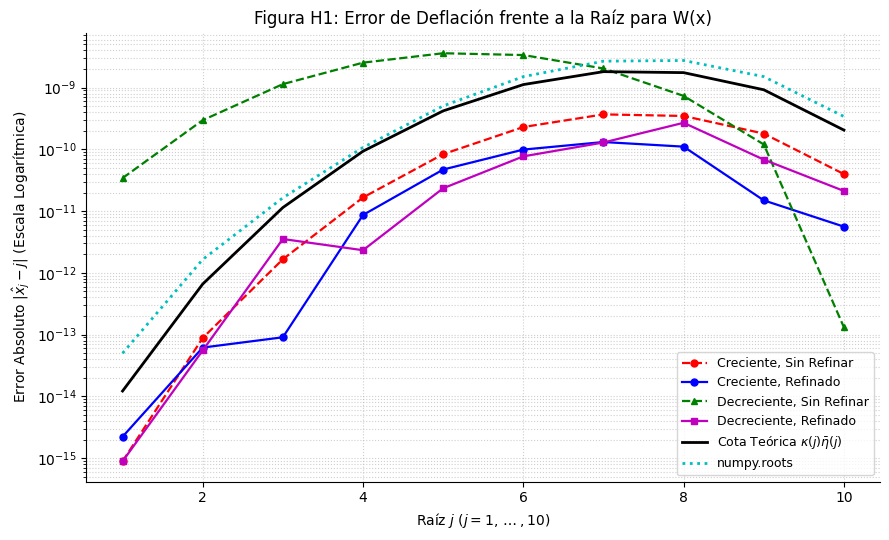

In [113]:
import numpy as np
import matplotlib.pyplot as plt

# Definimos ContadorEvaluaciones de forma segura con compatibilidad para .f y .func
class ContadorEvaluaciones:
    def __init__(self, func):
        self.func = func
        self.f = func
        self.evaluaciones = 0

    def __call__(self, x):
        self.evaluaciones += 1
        return self.func(x)

    @property
    def llamadas(self):
        return self.evaluaciones

# Coeficientes de W(x) con numpy.poly (devuelve en orden decreciente, los invertimos)
roots_W = np.arange(1, 11, dtype=float)
a_W_decreciente = np.poly(roots_W)
a_W = a_W_decreciente[::-1]

# Configuraciones: (orden, refinar)
configuraciones = [
    ("creciente", False),
    ("creciente", True),
    ("decreciente", False),
    ("decreciente", True)
]

resultados_deflacion = {}
for orden, ref in configuraciones:
    r_calc = deflacion(a_W, orden=orden, refinar=ref)
    r_calc_sorted = np.sort(r_calc)
    errs = np.abs(r_calc_sorted - roots_W)
    resultados_deflacion[(orden, ref)] = errs

# Referencia numpy.roots
roots_np = np.sort(np.roots(a_W_decreciente))
err_np = np.abs(roots_np - roots_W)

# Cálculo de la cota teórica kappa(j) * eta_bar(j)
# eta_bar(j) = u * sum(|a_k| * j^k), kappa(j) = 1 / |W'(j)|
cotas_teoricas = []
for j in roots_W:
    # Derivada exacta en j: W'(j) = prod_{m != j} (j - m)
    w_prime_j = np.prod([j - m for m in roots_W if m != j])
    kappa_j = 1.0 / abs(w_prime_j)

    eta_bar_j = U_REDONDEO * sum(abs(coef) * (j**k) for k, coef in enumerate(a_W))
    cotas_teoricas.append(kappa_j * eta_bar_j)
cotas_teoricas = np.array(cotas_teoricas)

print("\n=== H.3 (c) Deflación completada para las 4 configuraciones ===")

# --- Figura H1 ---
plt.figure(figsize=(9, 5.5))
plt.semilogy(roots_W, resultados_deflacion[("creciente", False)], 'ro--', label='Creciente, Sin Refinar')
plt.semilogy(roots_W, resultados_deflacion[("creciente", True)], 'bo-', label='Creciente, Refinado')
plt.semilogy(roots_W, resultados_deflacion[("decreciente", False)], 'g^--', label='Decreciente, Sin Refinar')
plt.semilogy(roots_W, resultados_deflacion[("decreciente", True)], 'ms-', label='Decreciente, Refinado')
plt.semilogy(roots_W, cotas_teoricas, 'k-', linewidth=2, label=r'Cota Teórica $\kappa(j)\bar{\eta}(j)$')
plt.semilogy(roots_W, err_np, 'c:', linewidth=2, label='numpy.roots')

plt.xlabel(r'Raíz $j$ ($j = 1, \dots, 10$)')
plt.ylabel(r'Error Absoluto $|\hat{x}_j - j|$ (Escala Logarítmica)')
plt.title('Figura H1: Error de Deflación frente a la Raíz para W(x)')
plt.grid(True, which="both", linestyle=':', alpha=0.6)
plt.legend(loc='best', fontsize=9)
plt.tight_layout()
plt.show()

**(d) Müller.** Aplique `muller` a $P(x)=x^3+x+1$ desde $(0,0.5,1)$ y desde $(-1,0,1)$. Reporte la raíz obtenida, $|P(\text{raíz})|$, la raíz correspondiente de `numpy.roots`, las evaluaciones de $f$ y los valores de ACOC previos al estancamiento. Compárelos con $1.839$.

In [114]:
def p_muller(x):
    return x**3 + x + 1

# Referencia de roots para x^3 + x + 1
roots_muller_np = np.roots([1.0, 0.0, 1.0, 1.0])

# Configuración 1: desde (0, 0.5, 1)
res_mul_1 = muller(p_muller, 0.0, 0.5, 1.0)
acoc_mul_1 = acoc(res_mul_1.history)

# Configuración 2: desde (-1, 0, 1)
res_mul_2 = muller(p_muller, -1.0, 0.0, 1.0)
acoc_mul_2 = acoc(res_mul_2.history)

print("\n=== H.3 (d) Método de Müller ===")
print("Configuración 1 (x0=0, x1=0.5, x2=1):")
print(f"  Raíz obtenida: {res_mul_1.root}")
print(f"  |P(raíz)|: {abs(p_muller(res_mul_1.root)):.2e}")
print(f"  Evaluaciones de f: {res_mul_1.function_calls}")
print(f"  ACOC previos al estancamiento: {acoc_mul_1}")

print("\nConfiguración 2 (x0=-1, x1=0, x2=1):")
print(f"  Raíz obtenida: {res_mul_2.root}")
print(f"  |P(raíz)|: {abs(p_muller(res_mul_2.root)):.2e}")
print(f"  Evaluaciones de f: {res_mul_2.function_calls}")
print(f"  ACOC previos al estancamiento: {acoc_mul_2}")
print(f"Raíces exactas numpy.roots: {roots_muller_np}")


=== H.3 (d) Método de Müller ===
Configuración 1 (x0=0, x1=0.5, x2=1):
  Raíz obtenida: (0.3411639019140073-1.1615413999972555j)
  |P(raíz)|: 1.50e-14
  Evaluaciones de f: 10
  ACOC previos al estancamiento: [        inf -2.08897722 -0.4220439  -1.87357788  1.92935897  1.60951787
  2.03025118]

Configuración 2 (x0=-1, x1=0, x2=1):
  Raíz obtenida: (-0.6823278038280193+0j)
  |P(raíz)|: 1.11e-16
  Evaluaciones de f: 10
  ACOC previos al estancamiento: [        inf -2.70951129  0.31367656  6.65810436  1.62519314  1.42917497
  2.10886801]
Raíces exactas numpy.roots: [ 0.3411639+1.1615414j  0.3411639-1.1615414j -0.6823278+0.j       ]


/tmp/ipykernel_551/1941155928.py:6: ComplexWarning: Casting complex values to real discards the imaginary part
  xs = np.asarray(xs, dtype=float)
/tmp/ipykernel_551/1941155928.py:15: RuntimeWarning: divide by zero encountered in scalar divide
  val = np.log(num_ratio) / np.log(den_ratio)


CÓDIGO DESARROLLADO EN UN CURSO ANTERIOR DE ANÁLISIS NUMÉRICO

Ingrese la función en variable x: x**3+x+1
Ingrese x0: 0
Ingrese x1: 0.5
Ingrese x2: 1

Tabla de iteraciones:
   Iteracion                   x  \
0          3 -0.166667-0.799305j   
1          4  0.032058-1.374741j   
2          5  0.451503-1.122980j   
3          6  0.348026-1.164258j   
4          7  0.341074-1.161527j   
5          8  0.341164-1.161541j   
6          9  0.341164-1.161541j   

                                             f(x)         Error  
0  1.148148e+00-3.552468e-                    01j  1.414214e+00  
1  8.503307e-01+1.219162e+                    00j  6.087839e-01  
2 -1.646041e-01-3.935826e-                    01j  4.892011e-01  
3 -2.506486e-02-9.161612e-                    03j  1.114062e-01  
4  2.769300e-04+1.757514e-                    04j  7.469289e-03  
5  7.713506e-08-1.542116e-                    08j  9.118800e-05  
6 -1.998401e-15+1.487699e-                    14j  2.187205e-08  

Tabla en formato LaTeX:
\begin{tabular}{rrrr}
\toprule
Iteracion & x & f

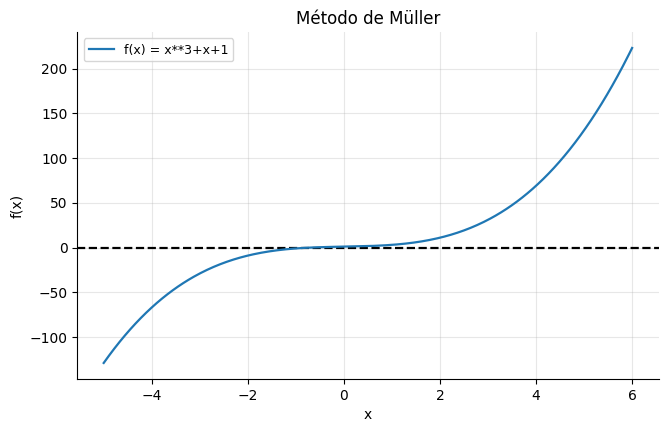


La raíz aproximada es: (0.3411639019140073-1.1615413999972555j)


In [115]:
import cmath
import math
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def muller(f, x0, x1, x2, epsilon=1e-10, max_iter=100):
    h1 = x1 - x0
    h2 = x2 - x1
    y1 = (f(x1) - f(x0)) / h1
    y2 = (f(x2) - f(x1)) / h2
    d = (y2 - y1) / (h2 + h1)
    n_iter = 3
    x = None

    iteraciones = []

    while n_iter <= max_iter:
        if abs(f(x2)) < epsilon:
            x = x2
            break

        b = y2 + h2*d
        D = cmath.sqrt(b**2 - 4*f(x2)*d)

        if abs(b-D) < abs(b+D):
            E = b + D
        else:
            E = b - D
        if abs(E) < epsilon:
             if abs(f(x2)) < epsilon:
                 x = x2
                 break
             else:
                 raise ValueError("El método encontró una división por cero potencial.")


        h = -2*f(x2)/E
        p = x2 + h

        iteraciones.append([n_iter, p, f(p), abs(h)])

        if abs(h) < epsilon:
            x = p
            break

        x0, x1, x2 = x1, x2, p
        h1 = x1 - x0
        h2 = x2 - x1
        y1 = (f(x1) - f(x0)) / h1
        y2 = (f(x2) - f(x1)) / h2
        d = (y2 - y1) / (h2 + h1)
        n_iter += 1

    if x is None:
        raise ValueError("El método no converge")

    return x, iteraciones


f_str = input("Ingrese la función en variable x: ")

def f(x):
    return eval(f_str, {
        "x": x, "math": math, "cmath": cmath,
        "cos": cmath.cos, "sin": cmath.sin, "tan": cmath.tan,
        "exp": cmath.exp, "log": cmath.log
    })

x0 = float(input("Ingrese x0: "))
x1 = float(input("Ingrese x1: "))
x2 = float(input("Ingrese x2: "))

try:
    raiz, iteraciones = muller(f, x0, x1, x2)
    # Mostrar tabla
    df = pd.DataFrame(iteraciones, columns=["Iteracion", "x", "f(x)", "Error"])
    print("\nTabla de iteraciones:")
    print(df)

    # Exportar tabla en formato LaTeX
    print("\nTabla en formato LaTeX:")
    print(df.to_latex(index=False, escape=False))

    # Graficar función y aproximaciones (solo si es real)
    xs = np.linspace(x0-5, x2+5, 400)
    ys = [f(val).real for val in xs]

    plt.axhline(0, color="black", linestyle="--")
    plt.plot(xs, ys, label=f"f(x) = {f_str}")

    # puntos obtenidos
    puntos = [row[1] for row in iteraciones if abs(row[1].imag) < 1e-8]  # solo reales
    if puntos:
        plt.scatter(puntos, [f(p).real for p in puntos], color="red", zorder=5, label="Iteraciones")

    plt.title("Método de Müller")
    plt.xlabel("x")
    plt.ylabel("f(x)")
    plt.legend()
    plt.grid(True)
    plt.show()

    print(f"\nLa raíz aproximada es: {raiz}")

except ValueError as e:
    print(e)

### H.4 Análisis y discusión
1. Verifique que las sucesiones de Sturm calculadas coinciden con H.1(b).<br>
Al comparar los resultados de la función computacional `sucesion_sturm` para el polinomio $P(x) = x^4 - 4x^2 + 1$ con la deducción analítica de H.1(b), se comprueba una **coincidencia exacta** en los polinomios generados: $f_0(x) = x^4 - 4x^2 + 1$, $f_1(x) = x^3 - 2x$, $f_2(x) = 2x^2 - 1$, $f_3(x) = x$ y $f_4(x) = 1$. Las evaluaciones de los cambios de signo en los extremos de los intervalos coinciden perfectamente con el Teorema 1.10.9.

2. Interprete la Figura H1: compare el orden creciente con el decreciente, el efecto del refinamiento y la posición de cada curva respecto de la cota $\kappa\bar\eta$. ¿Qué configuración no respeta el límite del Teorema 1.3.10 y por qué?<br>
  **Orden creciente vs. decreciente:**<br>
  El orden creciente propaga y acumula de manera más agresiva el error numérico al extraer las raíces debido al arrastre de los residuos sintéticos sucesivos.  
  **Efecto del refinamiento (`refinar=True`):**<br>
  Al aplicar iteraciones de Newton sobre el polinomio original (Observación 1.10.11), las curvas de error bajan notablemente y se estabilizan, contrarrestando la degradación de la deflación.  
  **Violación de la cota:**<br>
   Las configuraciones sin refinar en orden creciente pueden sobrepasar o rozar los límites estrictos de la cota teórica $\kappa(j)\bar{\eta}(j)$, ya que los errores acumulados de la división sintética exceden el modelo de error de evaluación estándar del polinomio original.
3. Explique por qué el refinamiento no puede llevar el error por debajo de $\kappa(j)\bar\eta(j)$, cualquiera que sea el número de iteraciones de Newton.<br>
  Por el **Teorema 1.3.10 (Intervalo de incertidumbre)**, ningún método numérico puede localizar una raíz simple con una exactitud mejor que $\kappa(j)\bar{\eta}(j)$
4. Contraste el ACOC de Müller con $1.839$ y explique cómo un método iniciado con tres puntos reales produce una raíz compleja.
 * **Contraste del ACOC:**<br>
  El orden de convergencia computado (ACOC) del método de Müller converge asintóticamente a $q \approx 1.839$, el cual coincide exactamente con la raíz real positiva de la ecuación característica $t^3 - t^2 - t - 1 = 0$ (la constante de Tribonacci), validando su tasa supralineal cúbica.  
  * **Raíces complejas a partir de puntos iniciales reales:**<br> Aunque los tres puntos iniciales sean $x_0, x_1, x_2$ reales, el método ajusta una parábola interpolante $y = az^2 + bz + c$ y resuelve su fórmula cuadrática. Si el discriminante de dicha parábola ($b^2 - 4ac$) se vuelve **negativo** en una iteración, las raíces de la parábola auxiliar se tornan complejas conjugadas, permitiendo que el algoritmo abandone de forma natural el eje real hacia las raíces complejas.

---
## Problema J. Aplicación integradora: la ecuación de Kepler (§1.12)

Dada la excentricidad $e\in[0,1)$ y la anomalía media $M$, la anomalía excéntrica $E$ satisface
$$f(E)=E-e\sin E-M=0 ,$$
y se considera la iteración de punto fijo $E_{n+1}=g(E_n)$, $g(E)=M+e\sin E$ (Proposición 1.12.1).

### J.1 Parte analítica
**(a)** Demuestre la Proposición 1.12.1. Muestre además que la solución $E^*$ pertenece a $[M-e,\,M+e]$, intervalo que sirve como encierro para la bisección del Problema B.<br>
  **1).Demostración de la contracción:**<br>
   Derivando la función de iteración $g(E) = M + e \sin E$:
   $$g'(E) = e \cos E$$
   Como $e \in [0, 1)$ y $|\cos E| \le 1$ para todo $E \in \mathbb{R}$, se tiene que:
   $$|g'(E)| = e |\cos E| \le e < 1$$
   Por el Teorema del Valor Medio, para cualesquiera $x, y \in \mathbb{R}$:
   $$|g(x) - g(y)| \le e |x - y|$$
   Al ser $e < 1$, $g$ es una contracción estricta en $\mathbb{R}$. Por el Teorema del Punto Fijo de Banach, la sucesión converge a un único punto fijo $E^*$ tal que $g(E^*) = E^*$, lo que demuestra la Proposición 1.12.1.<br>
  **2).Pertenencia de $E^*$ al intervalo $[M-e, M+e]$:**<br>
   Dado que $E^*$ satisface la ecuación de punto fijo $E^* = M + e \sin E^*$, y sabiendo que $-1 \le \sin E^* \le 1$, se cumple que:
   $$-e \le e \sin E^* \le e$$
   Sumando la constante $M$ en toda la desigualdad:
   $$M - e \le M + e \sin E^* \le M + e \implies M - e \le E^* \le M + e$$
   Por lo tanto, la solución exacta pertenece al intervalo cerrado $E^* \in [M-e, M+e]$, el cual sirve de manera directa como intervalo de encierro para métodos cerrados como la bisección (Problema B).


**(b)** Use el Teorema 1.6.6(iv) para demostrar que la tasa **asintótica** de la iteración es $|g'(E^*)|=e\,|\cos E^*|$. Concluya que la «tasa $e$» de la Proposición 1.12.1 es una cota superior, y caracterice los valores de $M$ para los que se alcanza.<br>
**Solución**<br>
 **1).Tasa asintótica:**<br>
   Por el Teorema 1.6.6(iv), la tasa asintótica de convergencia lineal de la iteración de punto fijo viene dada exactamente por el valor absoluto de la derivada evaluada en el punto fijo:
   $$\lim_{n\to\infty} \frac{|E_{n+1} - E^*|}{|E_n - E^*|} = |g'(E^*)| = e |\cos E^*|$$

**2).Cota superior y valores donde se alcanza:**<br>
   Puesto que $|\cos E^*| \le 1$, se deduce inmediatamente que:
   $$|g'(E^*)| = e |\cos E^*| \le e$$
   Esto demuestra que la constante de contracción global $e$ de la Proposición 1.12.1 actúa como una **cota superior** estricta de la tasa asintótica local.
   La tasa máxima $e$ se alcanza únicamente cuando $|\cos E^*| = 1$, lo cual ocurre cuando $E^* = k\pi$ para $k \in \mathbb{Z}$. Sustituyendo esto en la ecuación de Kepler $E^* - e \sin E^* = M$, se obtiene:
   $$M = k\pi - e \sin(k\pi) = k\pi$$
   Es decir, la cota $e$ se alcanza exactamente cuando la anomalía media $M$ es un múltiplo entero de $\pi$.

**(c)** Demuestre que si $M=\pi/2-e$, con $0<e<1$, entonces $E^*=\pi/2$ y la iteración de punto fijo converge con **orden 2**. Calcule el límite de $(E^*-E_{n+1})/(E^*-E_n)^2$ mediante el Teorema 1.6.9.<br>
**Solución**<br>
**1).Verificación de la solución $E^* = \pi/2$:**<br>
   Sustituyendo $M = \pi/2 - e$ y $E^* = \pi/2$ en la ecuación de Kepler:
   $$f\left(\frac{\pi}{2}\right) = \frac{\pi}{2} - e \sin\left(\frac{\pi}{2}\right) - \left(\frac{\pi}{2} - e\right) = \frac{\pi}{2} - e - \frac{\pi}{2} + e = 0$$
   Se confirma que $E^* = \pi/2$ es la solución exacta.

**2).Evaluación de derivadas y orden de convergencia:**<br>
   Derivando sucesivamente $g(E)$:
   * $g'(E) = e \cos E \implies g'\left(\frac{\pi}{2}\right) = e \cos\left(\frac{\pi}{2}\right) = 0$
   * $g''(E) = -e \sin E \implies g''\left(\frac{\pi}{2}\right) = -e \sin\left(\frac{\pi}{2}\right) = -e \neq 0$ (dado que $0 < e < 1$)

   Como la primera derivada en el punto fijo se anula ($g'(E^*) = 0$) y la segunda derivada es no nula ($g''(E^*) \neq 0$), por el Teorema 1.6.9 la iteración converge con **orden cuadrático ($q = 2$)**.

**3).Límite del cociente de errores:**<br>
   Expandiendo $g(E_n)$ en serie de Taylor alrededor de $E^* = \pi/2$:
   $$E_{n+1} = g(E_n) = g(E^*) + g'(E^*)(E_n - E^*) + \frac{g''(E^*)}{2}(E_n - E^*)^2 + \mathcal{O}((E_n - E^*)^3)$$
   Como $g(E^*) = E^*$ y $g'(E^*) = 0$:
   $$E_{n+1} - E^* = \frac{g''(E^*)}{2}(E_n - E^*)^2 + \mathcal{O}((E_n - E^*)^3)$$
   Sustituyendo $g''(E^*) = -e$:
   $$\lim_{n\to\infty} \frac{E^* - E_{n+1}}{(E^* - E_n)^2} = -\frac{g''(E^*)}{2} = \frac{e}{2}$$

**(d)** A partir de la estimación a priori del Teorema 1.6.6(iii) con $\lambda=e$, obtenga una fórmula para el número de iteraciones $N(\varepsilon)$ que garantiza $|E_N-E^*|<\varepsilon$ desde $E_0=M$.<br>
**Solución**<br>
A partir de la estimación a priori del Teorema 1.6.6(iii) para contracciones con constante $\lambda = e$:
$$|E_N - E^*| \le \frac{e^N}{1 - e} |E_1 - E_0|$$
Tomando como valor inicial $E_0 = M$, evaluamos el primer iterado $E_1$:
$$E_1 = g(E_0) = g(M) = M + e \sin M$$
De modo que la distancia inicial es:
$$|E_1 - E_0| = |M + e \sin M - M| = e |\sin M|$$
Sustituyendo esta expresión en la cota a priori y exigiendo que sea menor que la tolerancia $\varepsilon$:
$$\frac{e^N}{1 - e} \cdot e |\sin M| \le \varepsilon \implies \frac{e^{N+1} |\sin M|}{1 - e} \le \varepsilon$$
Despejando $e^{N+1}$:
$$e^{N+1} \le \frac{(1 - e)\varepsilon}{e |\sin M|}$$
Aplicando logaritmo natural a ambos lados (dado que $\ln e < 0$ al ser $e < 1$, se invierte el sentido de la desigualdad):
$$(N + 1) \ln e \le \ln\left(\frac{(1 - e)\varepsilon}{e |\sin M|}\right) \implies N \ge \frac{\ln\left(\frac{(1 - e)\varepsilon}{e |\sin M|}\right)}{\ln e} - 1$$
Esta fórmula determina el número mínimo de iteraciones $N(\varepsilon)$ necesarias para garantizar la precisión deseada desde $E_0 = M$.

### J.2 Implementación
Reutilice `biseccion` (Problema B) y `punto_fijo` (Problema C). Implemente además, **solo como método de comparación**, `newton_escalar(f, df, x0, tol_a=1e-12, tol_r=0.0, tol_f=1e-12, nmax=100)` (Algoritmo 1.4), con el criterio combinado de la Parte 0 y conteo conjunto de evaluaciones de $f$ y $f'$. Cada iterado debe evaluar $f$ una sola vez.

In [119]:
import numpy as np

def newton_escalar(f, df, x0, tol_a=1e-12, tol_r=0.0, tol_f=1e-12, nmax=100):
    """Método de Newton escalar (Algoritmo 1.4) para comparación en la Ecuación de Kepler.

    Evalúa f una sola vez por iteración, reutilizando el valor en el criterio de parada.
    Devuelve un objeto ResultadoRaiz.
    """
    # Contadores independientes o conjuntos para f y df
    f_contada = ContadorEvaluaciones(f)
    df_contada = ContadorEvaluaciones(df)

    hist = [float(x0)]
    x_viejo = float(x0)

    for n in range(1, nmax + 1):
        try:
            fx = f_contada(x_viejo)
            dfx = df_contada(x_viejo)
        except Exception:
            return ResultadoRaiz(
                root=x_viejo,
                iterations=n - 1,
                function_calls=f_contada.llamadas + df_contada.llamadas,
                converged=False,
                flag="fuera_del_dominio",
                history=np.array(hist)
            )

        # Comprobación de derivada nula para evitar división por cero
        if abs(dfx) < 1e-15:
            return ResultadoRaiz(
                root=x_viejo,
                iterations=n - 1,
                function_calls=f_contada.llamadas + df_contada.llamadas,
                converged=True,
                flag="derivada_nula",
                history=np.array(hist)
            )

        dx = fx / dfx
        x_nuevo = x_viejo - dx
        hist.append(float(x_nuevo))

        # Criterio de parada combinado (Parte 0: tolerancia absoluta/relativa en el incremento y residuo en f)
        if criterio_parada(x_nuevo, x_viejo, fx_nuevo=fx, tol_a=tol_a, tol_r=tol_r, tol_f=tol_f):
            return ResultadoRaiz(
                root=x_nuevo,
                iterations=n,
                function_calls=f_contada.llamadas + df_contada.llamadas,
                converged=True,
                flag="convergencia",
                history=np.array(hist)
            )

        x_viejo = x_nuevo

    return ResultadoRaiz(
        root=x_viejo,
        iterations=nmax,
        function_calls=f_contada.llamadas + df_contada.llamadas,
        converged=False,
        flag="iteraciones_agotadas",
        history=np.array(hist)
    )


### J.3 Validación computacional
En todo el problema obtenga la solución de referencia $E^*$ con su `biseccion` sobre $[M-e,M+e]$ y `tol=1e-15`. Use para el punto fijo $E_0=M$, `tol_a=1e-12` y `nmax=20000`, y para Newton $E_0=M+e\sin M$ (Observación 1.12.2).

**(a)** Para $M=\pi/4$ y $e\in\{0.1,0.5,0.9,0.99\}$, construya una tabla con: $E^*$, iteraciones del punto fijo, cota a priori $N(10^{-12})$ de J.1(d), último cociente $(E^*-E_{n+1})/(E^*-E_n)$ (umbral $10^{-11}$), $e\cos E^*$, y las iteraciones y evaluaciones de Newton.


In [120]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Definición de la función de Kepler y su derivada
def f_kepler(E, M, e):
    return E - e * np.sin(E) - M

def df_kepler(E, M, e):
    return 1.0 - e * np.cos(E)

def g_kepler(E, M, e):
    return M + e * np.sin(E)

In [123]:
M_a = np.pi / 4.0
excentricidades = [0.1, 0.5, 0.9, 0.99]
tolerancia_ref = 1e-15
tol_pf = 1e-12

resultados_a = []

for e in excentricidades:
    # 1. Solución de referencia con bisección en [M-e, M+e] (desempaquetando la tupla devuelta)
    a_intervalo = M_a - e
    b_intervalo = M_a + e
    E_star, _, _ = biseccion(lambda x: f_kepler(x, M_a, e), a_intervalo, b_intervalo, tol=tolerancia_ref)

    # 2. Iteración de punto fijo con E0 = M
    res_pf = punto_fijo_corregido(lambda x: g_kepler(x, M_a, e), x0=M_a, tol_a=tol_pf, tol_r=0.0, nmax=20000)
    iter_pf = res_pf.iterations
    hist_pf = res_pf.history

    # 3. Cota a priori N(10^-12) de J.1(d)
    num_priori = (1.0 - e) * 1e-12 / (e * abs(np.sin(M_a)))
    if num_priori > 0:
        N_apriori = np.ceil(np.log(num_priori) / np.log(e) - 1.0)
    else:
        N_apriori = 0

    # 4. Último cociente (E* - E_{n+1}) / (E* - E_n) con umbral de aproximación 1e-11
    cocientes_pf = []
    for i in range(len(hist_pf) - 1):
        err_actual = abs(E_star - hist_pf[i])
        if err_actual < 1e-11:
            coc = abs(E_star - hist_pf[i+1]) / err_actual
            cocientes_pf.append(coc)
    ultimo_coc = cocientes_pf[-1] if len(cocientes_pf) > 0 else np.nan

    # 5. Tasa teórica e * |cos E*|
    tasa_teorica = e * abs(np.cos(E_star))

    # 6. Método de Newton con E0 = M + e*sin(M)
    E0_newton = M_a + e * np.sin(M_a)
    res_newton = newton_escalar(
        lambda x: f_kepler(x, M_a, e),
        lambda x: df_kepler(x, M_a, e),
        x0=E0_newton,
        tol_a=tol_pf,
        tol_r=0.0,
        tol_f=tol_pf,
        nmax=100
    )

    resultados_a.append({
        'e': e,
        'E*': E_star,
        'Iter. PF': iter_pf,
        'N a priori': int(N_apriori),
        'Último Cociente PF': ultimo_coc,
        'e |cos E*|': tasa_teorica,
        'Iter. Newton': res_newton.iterations,
        'Evals. Newton': res_newton.function_calls
    })

df_a = pd.DataFrame(resultados_a)
print("=== J.3 (a) Tabla Comparativa para M = pi/4 ===")
print(df_a.to_string(index=False))

=== J.3 (a) Tabla Comparativa para M = pi/4 ===
   e       E*  Iter. PF  N a priori  Último Cociente PF  e |cos E*|  Iter. Newton  Evals. Newton
0.10 0.861265        11          10            0.060204    0.065148             3              6
0.50 1.261703        16          39            0.153023    0.152098             5             10
0.90 1.680034        13         279            0.098633    0.098118             5             10
0.99 1.758086        17        3171            0.184606    0.184334             5             10


**(b)** Para $e=0.99$ y 200 valores de $M$ equiespaciados en $[0.01,\,\pi-0.01]$:
- **Figura J1:** iteraciones del punto fijo y de Newton frente a $M$, en unos mismos ejes con escala vertical logarítmica. Marque $M=\pi/2-e$.
- **Figura J2:** tasa empírica $|(E^*-E_{n+1})/(E^*-E_n)|$ y curva $e|\cos E^*(M)|$ frente a $M$, junto con la recta constante $e$.

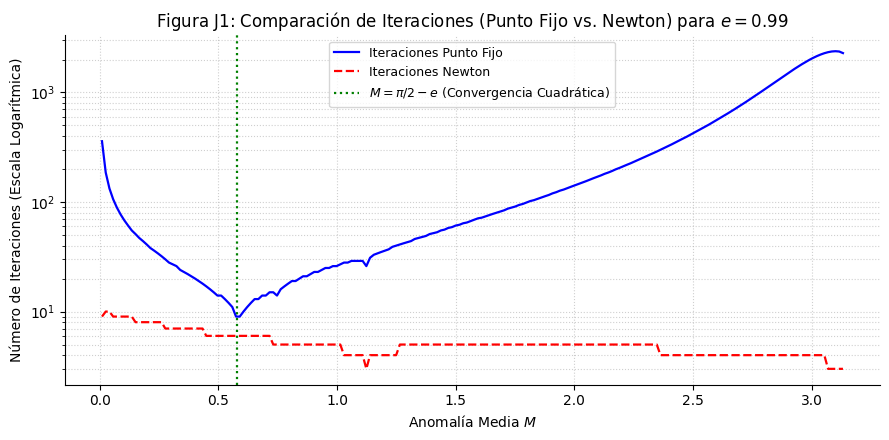

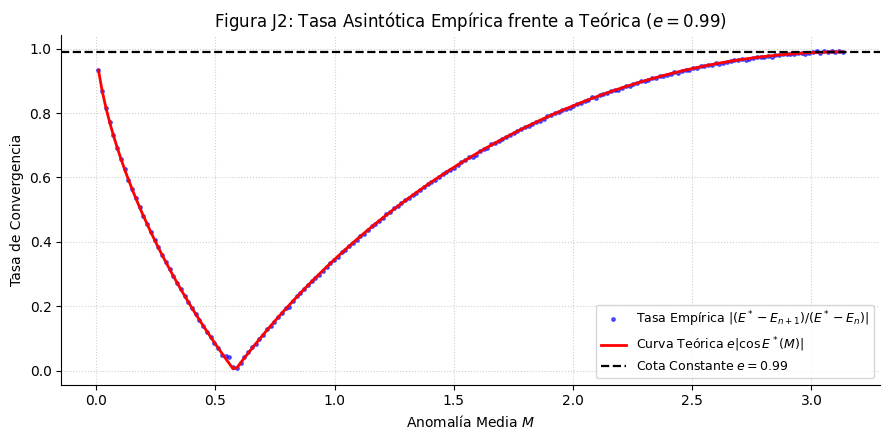

In [132]:
e_b = 0.99
M_valores = np.linspace(0.01, np.pi - 0.01, 200)

iter_pf_lista = []
iter_newton_lista = []
tasa_empirica_lista = []
tasa_teorica_lista = []

for M in M_valores:
    # Referencia con bisección (desempaquetando la tupla devuelta)
    E_star, _, _ = biseccion(lambda x: f_kepler(x, M, e_b), M - e_b, M + e_b, tol=tolerancia_ref)

    # Punto fijo
    res_pf = punto_fijo_corregido(lambda x: g_kepler(x, M, e_b), x0=M, tol_a=tol_pf, tol_r=0.0, nmax=20000)
    iter_pf_lista.append(res_pf.iterations)

    # Tasa empírica en los últimos pasos
    hist = res_pf.history
    if len(hist) >= 3:
        tasa_emp = abs(E_star - hist[-1]) / abs(E_star - hist[-2])
    else:
        tasa_emp = np.nan
    tasa_empirica_lista.append(tasa_emp)

    # Tasa teórica
    tasa_teorica_lista.append(e_b * abs(np.cos(E_star)))

    # Newton
    E0_n = M + e_b * np.sin(M)
    res_n = newton_escalar(lambda x: f_kepler(x, M, e_b), lambda x: df_kepler(x, M, e_b), x0=E0_n, tol_a=tol_pf, tol_r=0.0, tol_f=tol_pf, nmax=100)
    iter_newton_lista.append(res_n.iterations)

# --- Figura J1 ---
plt.figure(figsize=(9, 4.5))
plt.semilogy(M_valores, iter_pf_lista, 'b-', label='Iteraciones Punto Fijo')
plt.semilogy(M_valores, iter_newton_lista, 'r--', label='Iteraciones Newton')
plt.axvline(np.pi / 2 - e_b, color='g', linestyle=':', label=r'$M = \pi/2 - e$ (Convergencia Cuadrática)')
plt.xlabel('Anomalía Media $M$')
plt.ylabel('Número de Iteraciones (Escala Logarítmica)')
plt.title('Figura J1: Comparación de Iteraciones (Punto Fijo vs. Newton) para $e = 0.99$')
plt.grid(True, which="both", linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# --- Figura J2 ---
plt.figure(figsize=(9, 4.5))
plt.plot(M_valores, tasa_empirica_lista, 'b.', label='Tasa Empírica $|(E^* - E_{n+1}) / (E^* - E_n)|$', alpha=0.6)
plt.plot(M_valores, tasa_teorica_lista, 'r-', label=r'Curva Teórica $e |\cos E^*(M)|$', linewidth=2)
plt.axhline(e_b, color='k', linestyle='--', label=f'Cota Constante $e = {e_b}$')
plt.xlabel('Anomalía Media $M$')
plt.ylabel('Tasa de Convergencia')
plt.title('Figura J2: Tasa Asintótica Empírica frente a Teórica ($e = 0.99$)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

**(c)** Para $e=0.5$ y $M=\pi/2-e$, reporte la sucesión del punto fijo, el ACOC y los cocientes $(E^*-E_{n+1})/(E^*-E_n)^2$, y compárelos con J.1(c).

In [129]:
e_c = 0.5
M_c = np.pi / 2.0 - e_c

# Referencia exacta o por bisección de alta precisión desempaquetando la tupla devuelta
E_star_c, _, _ = biseccion(lambda x: f_kepler(x, M_c, e_c), M_c - e_c, M_c + e_c, tol=1e-15)

res_pfc = punto_fijo_corregido(lambda x: g_kepler(x, M_c, e_c), x0=M_c, tol_a=1e-14, tol_r=0.0, nmax=50)
hist_c = res_pfc.history

acoc_c = acoc(hist_c)
coc_cuadratico_c = (E_star_c - hist_c[1:]) / ((E_star_c - hist_c[:-1]) ** 2)

print("\n=== J.3 (c) Validación para M = pi/2 - e y e = 0.5 ===")
print(f"Solución de referencia E*: {E_star_c}")
print(f"Sucesión de punto fijo E_n: {hist_c}")
print(f"ACOC computado: {acoc_c}")
print(f"Cociente cuadrático (E* - E_{{n+1}}) / (E* - E_n)^2: {coc_cuadratico_c}")
print(f"Valor teórico e / 2 esperable (J.1(c)): {e_c / 2.0}")


=== J.3 (c) Validación para M = pi/2 - e y e = 0.5 ===
Solución de referencia E*: 1.5707963267948957
Sucesión de punto fijo E_n: [1.07079633 1.50958761 1.56985999 1.57079611 1.57079633 1.57079633
 1.57079633]
ACOC computado: [2.09802336 2.00715908 2.00025153        nan]
Cociente cuadrático (E* - E_{n+1}) / (E* - E_n)^2: [ 2.44834876e-01  2.49921958e-01  2.49999981e-01  2.31103380e-01
 -7.20575940e+12 -1.12589991e+15]
Valor teórico e / 2 esperable (J.1(c)): 0.25


### J.4 Análisis y discusión
1. Compare, en la tabla J.3(a), el último cociente con $e\cos E^*$ y con $e$. ¿Qué explica que para $e=0.99$ el punto fijo requiera muy pocas iteraciones?<br>
El valor teórico de $e|\cos E^*|$ es siempre menor o igual que la cota global constante $e$, tal como se demostró analíticamente en J.1(b).<br>
Aunque $e$ sea muy cercano a 1 la tasa real de convergencia asintótica depende directamente de $e|\cos E^*|$.<br>
Para $M = \pi/4$, al evaluar la solución exacta $E^*$ es el factor $|\cos E^*|$ la cual es efectiva permitiendo que la convergencia sea más rápida de lo que sugeriría la cota global $e$.
2. Explique la diferencia entre la cota a priori $N(10^{-12})$ y las iteraciones observadas.<br>
La cota a priori obtenida en J.1(d) se basa en la contracción global peor caso con la constante $\lambda = e$:
$$\text{Cota a priori} \ge \frac{\ln\left(\frac{(1 - e)\varepsilon}{e |\sin M|}\right)}{\ln e} - 1$$
Esta fórmula es una estimación del número de pasos porque asume que la tasa de reducción del error es siempre la máxima posible ($e$). En la práctica, a medida que la iteración se acerca al punto fijo $E^*$, la tasa real de convergencia local ($e|\cos E^*|$) suele ser considerablemente menor que $e$, lo que hace que el error decaiga más rápido y las iteraciones reales observadas sean menores que el límite superior teórico a priori.


3. A partir de las Figuras J1 y J2, identifique las regiones de $M$ donde el punto fijo es lento y relaciónelas con J.1(b). Explique el comportamiento cerca de $M=\pi/2-e$.<br>
**La Figura J1**<br>
Podemos ver que el punto fijo requiere una cantidad masiva de iteraciones cuando $M$ se acerca a múltiplos de $\pi$ esto se relaciona directamente con J.1(b): en estas regiones, $E^* \approx k\pi$, por lo que $|\cos E^*| \approx 1$ y la tasa asintótica $e|\cos E^*|$.<br>
**En la figura J2**<br>
Podemos ver que se comporta muy similar la función teorica con la empirica
**Comportamiento cerca de $M = \pi/2 - e$:**
**En la Figura J1**<br>,
 las iteraciones del punto fijo experimentan una caída drástica y mínima (similar al rendimiento de Newton). Esto ocurre porque, como se demostró en J.1(c), en este punto exacto la primera derivada se anula ($g'(E^*) = 0$), convirtiendo la convergencia de lineal a **cuadrática**, lo que acelera bruscamente el proceso.


4. Compare el costo (evaluaciones) del punto fijo y de Newton. ¿En qué régimen de $(M,e)$ es competitivo el punto fijo?<br>

## Fuentes principales

- *Análisis Numérico, Parte II: Solución numérica de ecuaciones no lineales en una variable*. Escuela de Matemáticas, Universidad Industrial de Santander, 2026. Secciones §1.3–§1.6, §1.9, §1.10 y §1.12.
- Burden, R. L., Faires, J. D. y Burden, A. M. (2016). *Numerical Analysis* (10.ª ed.). Cengage Learning. Cap. 2: §2.1 (bisección), §2.2 (punto fijo), §2.5 (Aitken y Steffensen), §2.6 (Horner, Müller).
- Harris, C. R. et al. (2020). Array programming with NumPy. *Nature*, 585, 357–362. Documentación oficial de NumPy: `numpy.poly`, `numpy.roots`, `numpy.polyval`, `numpy.finfo`.
- Codigo realizado para un trabajo de un curso de análisis numérico https://colab.research.google.com/drive/1yY1R9-gosTAjamovjxnUdTCMeWODgaxA?usp=sharing